# Telecom Customer Churn Prediction & Retention Strategy

*An end-to-end data science project: exploratory analysis, statistical hypothesis testing, machine-learning churn prediction, model interpretation, and a financially evaluated, test-first retention strategy.*

**Business question.** An anonymised telecom operator ("Company A") loses customers every month. Its churn risk rises sharply from around month 10 of tenure and peaks at months 11–12; handset age and service quality add further risk. *Can a machine-learning model identify and prioritise customers for cost-effective retention action — and under what conditions would such a programme actually pay off?*

**Data.** About 100,000 customers of an anonymised telecom operator, in two tables (`Client.csv`, `Record.csv`) joined on `Customer_ID`. The raw files are **not redistributed** with this repository; see `data/README.md`. Company A is not an identified real company, and this is an analytical project, not a production deployment.

**How to read the labels used throughout.** **[D]** dataset finding · **[B]** external benchmark (cited) · **[A]** scenario assumption. Financial results are scenarios, not guaranteed outcomes.

**Contents**
0. How to run this notebook
1. Setup and data loading
2. Hypothesis validation (tenure risk window, handset age)
3. Data preparation (quality checks, leakage review, prediction setup, train/test split)
4. Modelling: Logistic Regression vs LightGBM (5-fold cross-validation, overfitting checks)
5. Test-set evaluation (used once)
6. Business interpretation with SHAP and customer segments
7. Industry benchmarks and churn scenarios
8. Financial model: break-even analysis, probability calibration, sensitivity, randomised pilot design, audit
9. Freeze: save final results

All reported numbers are produced by the code in this notebook. The original CSV files are only read, never modified.

## 0. How to run this notebook

**Repository layout** (paths are resolved relative to the repository root, so the notebook works whether Jupyter is started from the root or from `notebooks/`):
```
telecom-churn-prediction-retention-strategy/
├── data/
│   ├── Client.csv      ← place the dataset files here (not included; see data/README.md)
│   └── Record.csv
├── notebooks/
│   └── telecom_churn_analysis.ipynb   ← this notebook
├── visuals/            ← charts written by the notebook
└── results/            ← metrics.json and summary tables written by the notebook
```

**Setup:** `pip install -r requirements.txt` (Python 3.10+), then open this notebook with Jupyter and run all cells. The package versions used for the verified run are printed in Section 1.

**Runtime:** about 5–10 minutes on a CPU (three models × 5-fold cross-validation, SHAP). Random seed 42 throughout, so results are reproducible.

## 1. Setup and data loading

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid", context="talk")
# Resolve the repository root (the folder that contains data/), so paths work from the root or from notebooks/
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir()), Path.cwd())
FIG_DIR = ROOT / "visuals"; FIG_DIR.mkdir(exist_ok=True)

import sys, sklearn, lightgbm, statsmodels, scipy, shap, matplotlib
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| lightgbm", lightgbm.__version__, "| statsmodels", statsmodels.__version__, "| scipy", scipy.__version__,
      "| shap", shap.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | lightgbm 4.7.0 | statsmodels 0.15.0 | scipy 1.18.1 | shap 0.54.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
# Google Colab: clone the repository, %cd into it, and place Client.csv and Record.csv in data/ (see data/README.md).
DATA_DIR = ROOT / "data"     # relative to the repository root
missing = [f for f in ("Client.csv", "Record.csv") if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing} in {DATA_DIR.resolve()}. Place Client.csv and Record.csv "
                            "in the repository's data/ folder (see data/README.md).")
client = pd.read_csv(DATA_DIR / "Client.csv")
record = pd.read_csv(DATA_DIR / "Record.csv")
print("Client:", client.shape, "| Record:", record.shape)

# Verify the join instead of assuming it
for name, t in [("Client", client), ("Record", record)]:
    print(f"{name}: duplicate IDs = {t.Customer_ID.duplicated().sum()}, duplicate rows = {t.duplicated().sum()}")
print("IDs present in both tables:", len(set(client.Customer_ID) & set(record.Customer_ID)))

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print("Merged:", df.shape)
print(df.churn.value_counts(normalize=True).round(4))

Client: (100000, 50) | Record: (100000, 51)
Client: duplicate IDs = 0, duplicate rows = 0


Record: duplicate IDs = 0, duplicate rows = 0
IDs present in both tables: 100000
Merged: (100000, 100)
churn
0    0.5044
1    0.4956
Name: proportion, dtype: float64


**Observations.** Both tables have exactly one row per customer and all 100,000 IDs match, so the 1:1 merge is safe (`validate="one_to_one"` would raise an error otherwise).
Churn is ~50/50. Real telecom churn is far lower, so this sample was almost certainly balanced on purpose: **churn rates here are valid for comparing groups, not as Company A's real churn level.**

## 2. Hypothesis validation

**Hypothesis H1:** churn risk rises sharply around months 10–12 of tenure.
**Hypothesis H2:** handset age is associated with churn independently of tenure.

Method plan:
1. Churn rate per tenure month with 95% Wilson confidence intervals — is the jump bigger than noise?
2. Chi-square test — does the window differ from neighbouring months?
3. Logistic regression with progressively more controls — does the window effect survive?
4. Month-by-month model — does the shape hold without choosing the window in advance?
5. Handset-age effect inside and outside the window.

> **Correlation, not causation.** The dataset has no contract field. A rise at months 10–12 is *consistent with* a renewal or commitment period ending, but could also reflect promotions ending, billing reviews or how the sample was drawn. We describe it as a *risk window*, not as contract expiry.

### 2.1 Churn rate by tenure month

In [3]:
g = df[df.months <= 18].groupby("months").churn.agg(n="size", churners="sum")
g["rate"] = g.churners / g.n
g["ci_low"], g["ci_high"] = proportion_confint(g.churners, g.n, method="wilson")
print("Minimum tenure in data:", df.months.min(), "months")
g.round(3)

Minimum tenure in data: 6 months


,n,churners,rate,ci_low,ci_high
months,,,,,
6,1295,497,0.384,0.358,0.411
7,4979,1656,0.333,0.320,0.346
8,3728,1154,0.310,0.295,0.325
9,4066,1171,0.288,0.274,0.302
10,4313,1737,0.403,0.388,0.417
11,8029,5229,0.651,0.641,0.662
12,6033,3732,0.619,0.606,0.631
13,5651,3133,0.554,0.541,0.567
14,4552,2414,0.530,0.516,0.545


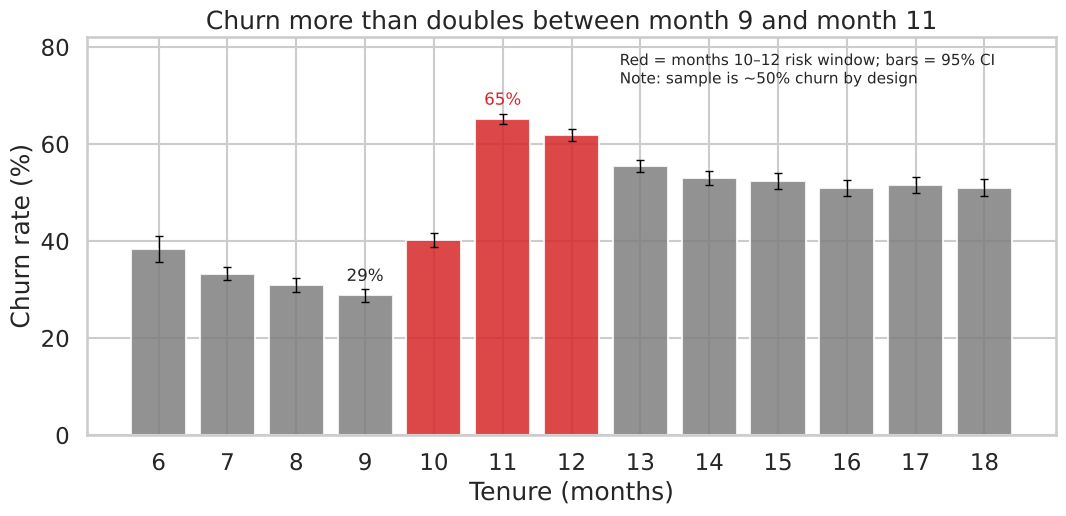

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ["#d62728" if m in (10, 11, 12) else "#7f7f7f" for m in g.index]
ax.bar(g.index, g.rate * 100, color=colors, alpha=0.85)
ax.errorbar(g.index, g.rate * 100,
            yerr=[(g.rate - g.ci_low) * 100, (g.ci_high - g.rate) * 100],
            fmt="none", ecolor="black", capsize=3, lw=1)
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn more than doubles between month 9 and month 11")
ax.set_xticks(g.index); ax.set_ylim(0, 82)
ax.annotate(f"{g.rate[9]*100:.0f}%", (9, g.rate[9]*100 + 3), ha="center", fontsize=12)
ax.annotate(f"{g.rate[11]*100:.0f}%", (11, g.rate[11]*100 + 3), ha="center", fontsize=12, color="#d62728")
ax.text(12.7, 79, "Red = months 10–12 risk window; bars = 95% CI\nNote: sample is ~50% churn by design", fontsize=11, va="top")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_churn_by_month.png", dpi=200); plt.show()

**Interpretation.** Churn falls to its lowest at month 9 (28.8%) and jumps to 65.1% at month 11. The confidence intervals are narrow (thousands of customers per month) and do not overlap, so this is not noise.
Note also that churn does **not** fall back afterwards: it settles at ~51–55%, permanently above the month 7–9 level. The pattern is *a step up, then a higher plateau* — not a temporary spike.
Months 11 and 12 are also the most common tenure values in the sample, which could partly reflect how the data was sampled (a limitation).

### 2.2 Is the window different from neighbouring months? (chi-square test)

In [5]:
s = df[df.months.between(7, 15)].copy()
s["group"] = np.where(s.months.between(10, 12), "months 10-12", "months 7-9 & 13-15")
ct = pd.crosstab(s.group, s.churn)
chi2, p, _, _ = chi2_contingency(ct)
print(ct, "\nChurn rate:", (ct[1] / ct.sum(1)).round(3).to_dict())
print(f"chi2 = {chi2:.1f}, p = {p:.2e}")

s2 = s[s.months.between(10, 15)]
ct2 = pd.crosstab(s2.months.between(10, 12), s2.churn)
chi2b, pb, _, _ = chi2_contingency(ct2)
print("\nWindow vs months 13-15 only:", (ct2[1] / ct2.sum(1)).round(3).to_dict(), f"p = {pb:.2e}")

churn                   0      1
group                           
months 10-12         7677  10698
months 7-9 & 13-15  15275  11536 
Churn rate: {'months 10-12': 0.582, 'months 7-9 & 13-15': 0.43}
chi2 = 1006.3, p = 7.49e-221

Window vs months 13-15 only: {False: 0.538, True: 0.582} p = 2.65e-15


**Interpretation.** Window vs all neighbours: 58% vs 43% churn, overwhelming significance. Window vs months 13–15 only: 58% vs 54% — real, but much smaller. The big contrast is *before vs after month 10*; the problem statement is worded accordingly ("risk begins around month 10, peaks at 11–12").

### 2.3 Does the window effect survive controls? (logistic regression)

Logistic regression estimates each variable's effect on churn **holding the others fixed**. Results are odds ratios (OR): OR 1.9 means the odds of churn are ~1.9× higher, all else equal; OR < 1 is protective.
We add controls in three stages. If the window effect were really caused by, say, older handsets, its OR would shrink toward 1 as controls are added.

Transformations: skewed amounts use `log1p`; handset age in years; handset price per \$100; usage change clipped to ±500% (extreme outliers) and expressed per 100 points. Negative `eqpdays` (impossible) are set to 0 here; Section 3 treats them as missing for modelling.

In [6]:
v = df.assign(
    win=df.months.between(10, 12).astype(int),
    log_months=np.log1p(df.months),
    eqp_years=df.eqpdays.clip(lower=0) / 365,
    hnd_price_100=df.hnd_price / 100,
    log_rev=np.log1p(df.rev_Mean.clip(lower=0)),
    log_mou=np.log1p(df.mou_Mean.clip(lower=0)),
    chg_mou=df.change_mou.clip(-500, 500) / 100,
    log_custcare=np.log1p(df.custcare_Mean),
    log_dropblk=np.log1p(df.drop_blk_Mean),
    refurb=(df.refurb_new == "R").astype(int),
)
ctrl = ["win", "log_months", "eqp_years", "hnd_price_100", "log_rev", "log_mou",
        "chg_mou", "log_custcare", "log_dropblk", "refurb"]
vd = v[["churn"] + ctrl + ["months"]].dropna()
print("Customers used in models:", len(vd))

forms = {
    "M1: window + tenure trend": "churn ~ win + log_months",
    "M2: + handset age": "churn ~ win + log_months + eqp_years",
    "M3: + price, revenue, usage, care, call failures, refurbished":
        "churn ~ " + " + ".join(ctrl),
}
rows, models = [], {}
for name, f in forms.items():
    m = smf.logit(f, vd).fit(disp=0, maxiter=200)
    models[name] = m
    lo, hi = np.exp(m.conf_int().loc["win"])
    rows.append([name, np.exp(m.params.win), lo, hi, m.pvalues.win, m.prsquared, m.mle_retvals["converged"]])
pd.DataFrame(rows, columns=["model", "window OR", "CI low", "CI high", "p", "pseudo R2", "converged"]).round(3)

Customers used in models: 98269


,model,window OR,CI low,CI high,p,pseudo R2,converged
0,M1: window + tenure trend,1.865,1.800,1.933,0.0,0.010,True
1,M2: + handset age,1.887,1.821,1.955,0.0,0.018,True
2,"M3: + price, revenue, usage, care, call failur...",1.922,1.854,1.992,0.0,0.027,True


,OR,lo,hi,p
In months 10-12,1.922,1.854,1.992,0.0
Tenure (log),1.079,1.043,1.117,0.0
Handset age (+1 year),1.336,1.302,1.372,0.0
Handset price (+$100),0.859,0.836,0.882,0.0
Monthly revenue (log),1.223,1.190,1.258,0.0
Monthly minutes (log),0.855,0.843,0.867,0.0
Usage change (+100 pts),0.956,0.950,0.963,0.0
Care calls (log),0.928,0.911,0.945,0.0
Dropped/blocked calls (log),1.103,1.086,1.121,0.0
Refurbished handset,1.256,1.205,1.309,0.0


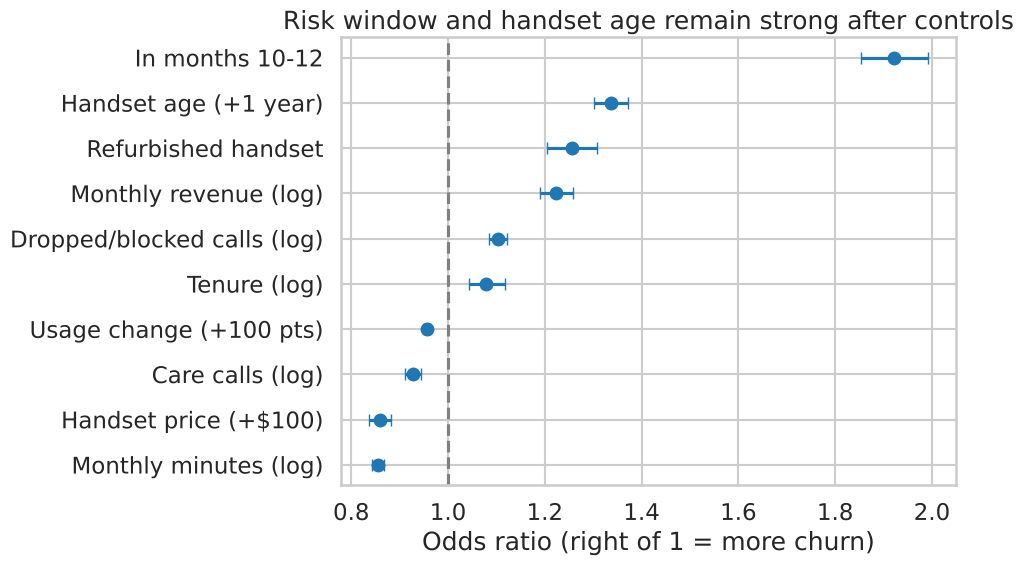

In [7]:
m3 = models[list(forms)[-1]]
labels = {"win": "In months 10-12", "log_months": "Tenure (log)", "eqp_years": "Handset age (+1 year)",
          "hnd_price_100": "Handset price (+$100)", "log_rev": "Monthly revenue (log)",
          "log_mou": "Monthly minutes (log)", "chg_mou": "Usage change (+100 pts)",
          "log_custcare": "Care calls (log)", "log_dropblk": "Dropped/blocked calls (log)",
          "refurb": "Refurbished handset"}
ort = pd.DataFrame({"OR": np.exp(m3.params), "lo": np.exp(m3.conf_int()[0]),
                    "hi": np.exp(m3.conf_int()[1]), "p": m3.pvalues}).loc[ctrl]
ort.index = [labels[i] for i in ort.index]
display(ort.round(3))

o = ort.sort_values("OR")
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(o.OR, range(len(o)), xerr=[o.OR - o.lo, o.hi - o.OR], fmt="o", color="#1f77b4", capsize=4)
ax.axvline(1, color="grey", ls="--")
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index)
ax.set_xlabel("Odds ratio (right of 1 = more churn)")
ax.set_title("Risk window and handset age remain strong after controls")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_odds_ratios.png", dpi=200); plt.show()

**Interpretation.** The window OR stays at ~1.9 in all three models — adding handset age, revenue, usage, call quality and care calls does not weaken it. Each extra year of handset age raises churn odds by ~33%; refurbished handsets and call failures add risk; pricier handsets reduce it.
Pseudo R² is low (≈ 0.03): these variables are **clear risk signals, but explain only a small part** of who churns. Prediction (Section 4–5) needs the full feature set.

### 2.4 Robustness: one coefficient per month (baseline = month 9)

In [8]:
r = vd[vd.months <= 18]
m4 = smf.logit("churn ~ C(months, Treatment(9)) + eqp_years + hnd_price_100 + log_rev + log_mou", r).fit(disp=0)
month_or = pd.Series({int(k.split("T.")[1].rstrip("]")): np.exp(val)
                      for k, val in m4.params.items() if "months" in k}).sort_index()
month_or.round(2).to_frame("OR vs month 9")

,OR vs month 9
6,1.62
7,1.28
8,1.13
10,1.63
11,4.48
12,3.86
13,2.89
14,2.59
15,2.47
16,2.30


**Interpretation.** Without pre-choosing a window, the model independently finds the peak at months 11–12 (OR ≈ 4.5 and 3.8 vs month 9), then a slow decline that stays well above pre-window levels. Month 6 is also somewhat elevated — a small group (1,295 customers) worth noting but outside our focus.

### 2.5 Does handset age matter independently — inside and outside the window?

In [9]:
hcontrols = "hnd_price_100 + log_rev + log_mou + chg_mou + log_custcare + log_dropblk + refurb"
out_w = vd[vd.months >= 13]
in_w = vd[vd.win == 1]
m_out = smf.logit(f"churn ~ eqp_years + log_months + {hcontrols}", out_w).fit(disp=0)
m_in = smf.logit(f"churn ~ eqp_years + {hcontrols}", in_w).fit(disp=0)
print(f"Tenure 13+  (n={len(out_w):,}): handset-age OR per year = {np.exp(m_out.params.eqp_years):.3f}, p = {m_out.pvalues.eqp_years:.1e}")
print(f"Months 10-12 (n={len(in_w):,}): handset-age OR per year = {np.exp(m_in.params.eqp_years):.3f}, p = {m_in.pvalues.eqp_years:.1e}")

w = df[df.months.between(10, 12)]
w.groupby(pd.qcut(w.eqpdays, 4)).churn.agg(customers="size", churn_rate="mean").round(3)

Tenure 13+  (n=66,160): handset-age OR per year = 1.357, p = 3.6e-98
Months 10-12 (n=18,185): handset-age OR per year = 1.593, p = 2.1e-12


,customers,churn_rate
eqpdays,,
"(-4.001, 281.0]",4596,0.541
"(281.0, 316.0]",4749,0.494
"(316.0, 340.0]",4547,0.671
"(340.0, 379.0]",4483,0.628


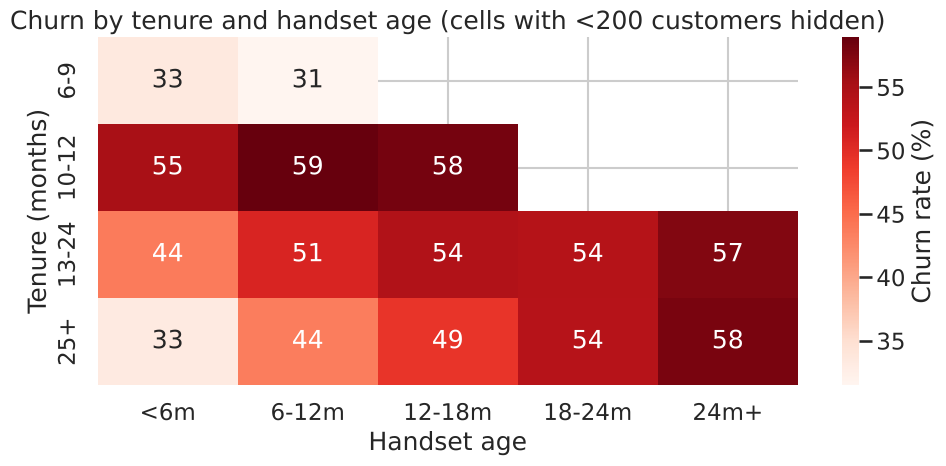

In [10]:
hm = df.assign(tenure=pd.cut(df.months, [5, 9, 12, 24, 61], labels=["6-9", "10-12", "13-24", "25+"]),
               handset=pd.cut(df.eqpdays, [-10, 180, 365, 540, 730, 2000],
                              labels=["<6m", "6-12m", "12-18m", "18-24m", "24m+"]))
piv = hm.pivot_table(index="tenure", columns="handset", values="churn", aggfunc="mean", observed=False)
cnt = hm.pivot_table(index="tenure", columns="handset", values="churn", aggfunc="size", observed=False)
piv = piv.where(cnt >= 200)   # hide cells with too few customers to be reliable
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(piv * 100, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_xlabel("Handset age"); ax.set_ylabel("Tenure (months)")
ax.set_title("Churn by tenure and handset age (cells with <200 customers hidden)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_tenure_handset_heatmap.png", dpi=200); plt.show()

**Interpretation.** Handset age has an independent effect both outside the window (OR ≈ 1.35/year) and inside it (OR ≈ 1.59/year; with a slightly different control set it was ≈ 1.42 — the direction and significance are stable, the exact size depends on which controls are included). Inside the window, handset age and month are partly tied together (a month-11 customer on the original phone also has an older phone), so these two signals overlap somewhat there.

> **Correction to earlier analysis.** An earlier exploratory table grouped all handsets under 1 year into one bin and suggested handset age "makes no difference" inside months 10–12. That was **wrong**: the coarse bin hid the variation. The finer analysis above shows a clear handset-age effect inside the window as well.

> **Caution.** "Customers with newer phones churn less" does **not** prove that giving a new phone prevents churn: loyal customers may simply be the ones who choose to upgrade (selection effect). Only a randomised pilot can measure whether an offer changes behaviour.

### 2.6 Hypothesis validation — summary

| Finding | Evidence | Status |
|---|---|---|
| Churn jumps from 28.8% (month 9) to 65.1% (month 11) | Per-month rates, non-overlapping 95% CIs | Verified |
| Window effect independent of observed factors | OR ≈ 1.9, stable across 3 models; month-by-month model peaks at 11–12 | Verified |
| Handset age independently associated with churn | OR ≈ 1.33/year overall; holds inside and outside window | Verified |
| Churn returns to low levels after month 12 | Rates stay ~51–55% | **Rejected** — it is a step up, not a spike |
| Window is very different from months 13–15 | 58% vs 54% | Weaker than first thought |
| Cause is contract expiry | No contract field | **Not testable** — described as a risk window |

**Limitations:** cross-sectional snapshot (different customers at each tenure, not the same customers over time); minimum tenure 6 months; ~50% churn by sampling design; observational data cannot show what an intervention would do.

## 3. Data preparation

### 3.1 Prediction setup (what the company knows, and when)
- **Prediction date (T):** the snapshot date of the data.
- **Features:** everything known at T — monthly averages, last-3/6-month averages, lifetime totals up to T, handset and account information.
- **Label:** `churn` = the customer left **31–60 days after T**.
- **Business meaning:** Company A scores customers at T and has roughly one month to act before the churn window opens.

Any feature that describes what happens *after* T would be **leakage** — information the company would not have when making the prediction. Leaked features make a model look excellent in testing and fail in real use.

### 3.2 Data types, duplicates, and missing values

In [11]:
print(df.dtypes.value_counts())
cat_cols_all = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("\nText (categorical) columns:", len(cat_cols_all))
print(df[cat_cols_all].nunique().sort_values(ascending=False).to_string())
print("\nDuplicate rows:", df.duplicated().sum(), "| Duplicate IDs:", df.Customer_ID.duplicated().sum())

float64    69
str        21
int64      10
Name: count, dtype: int64

Text (categorical) columns: 21
crclscod            54
area                19
ethnic              17
dwllsize            15
HHstatin             6
prizm_social_one     5
marital              5
dualband             4
new_cell             3
hnd_webcap           3
asl_flag             2
ownrent              2
refurb_new           2
infobase             2
dwlltype             2
kid0_2               2
kid3_5               2
kid6_10              2
kid11_15             2
kid16_17             2
creditcd             2



Duplicate rows: 0 | Duplicate IDs: 0


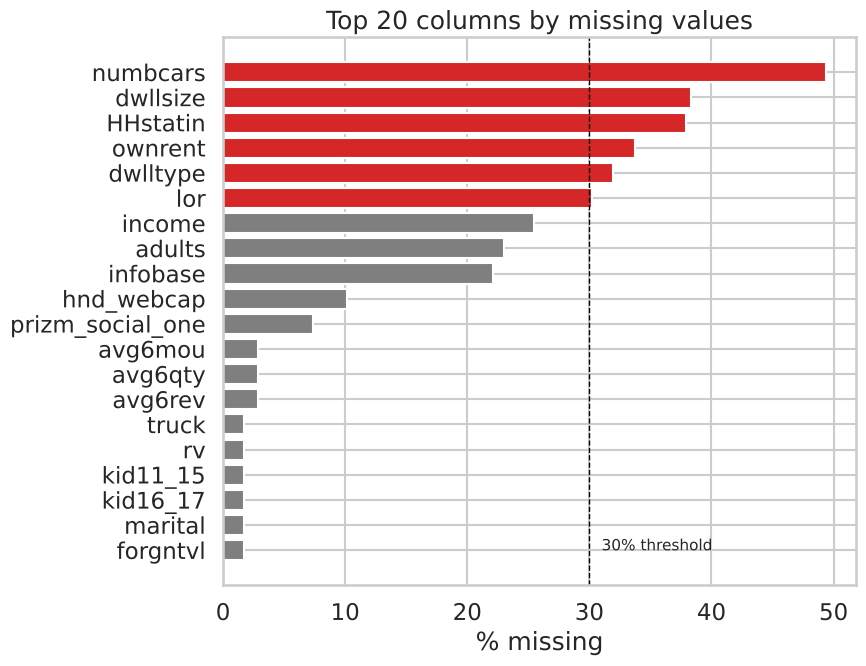

numbcars            0.494
dwllsize            0.383
HHstatin            0.379
ownrent             0.337
dwlltype            0.319
lor                 0.302
income              0.254
adults              0.230
infobase            0.221
hnd_webcap          0.102
prizm_social_one    0.074
avg6mou             0.028
avg6qty             0.028
avg6rev             0.028
truck               0.017
rv                  0.017
kid11_15            0.017
kid16_17            0.017
marital             0.017
forgntvl            0.017
dtype: float64

In [12]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(9, 7))
top = miss.head(20) * 100
ax.barh(top.index[::-1], top.values[::-1], color=["#d62728" if x > 30 else "#7f7f7f" for x in top.values[::-1]])
ax.axvline(30, color="black", ls="--", lw=1); ax.text(31, 0, "30% threshold", fontsize=11)
ax.set_xlabel("% missing"); ax.set_title("Top 20 columns by missing values")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_missing.png", dpi=200); plt.show()
miss.head(20).round(3)

**Observations.** Missingness concentrates in household/demographic fields bought from an external source (`numbcars` 49%, `dwllsize` 38%, `HHstatin` 38%, `ownrent` 34%, …). Usage fields are almost complete.

In [13]:
# Is missingness itself informative? 357 customers lack the whole monthly-usage block
usage_missing = df.rev_Mean.isna()
print("Customers with no monthly usage record:", usage_missing.sum())
print("Churn rate among them:", round(df.loc[usage_missing, "churn"].mean(), 3),
      "| everyone else:", round(df.loc[~usage_missing, "churn"].mean(), 3))

Customers with no monthly usage record: 357
Churn rate among them: 0.686 | everyone else: 0.495


**Interpretation.** The missing-usage group churns much more (68.6% vs ~50%). Missingness here is **a signal, not just a gap** — perhaps inactive or disconnected-billing accounts. We keep these customers and add a `usage_missing` flag rather than deleting them.

### 3.3 Invalid values and outliers

In [14]:
checks = {
    "eqpdays < 0 (impossible handset age)": (df.eqpdays < 0).sum(),
    "rev_Mean < 0": (df.rev_Mean < 0).sum(),
    "totmrc_Mean < 0": (df.totmrc_Mean < 0).sum(),
}
print(pd.Series(checks))
df[["rev_Mean", "mou_Mean", "custcare_Mean", "change_mou", "drop_blk_Mean", "eqpdays"]].describe(
    percentiles=[.01, .5, .99]).T.round(1)

eqpdays < 0 (impossible handset age)    133
rev_Mean < 0                              5
totmrc_Mean < 0                          23
dtype: int64


,count,mean,std,min,1%,50%,99%,max
rev_Mean,99643.0,58.7,46.3,-6.2,10.0,48.2,227.9,3843.3
mou_Mean,99643.0,513.6,525.2,0.0,0.0,355.5,2422.4,12206.8
custcare_Mean,100000.0,1.8,5.3,0.0,0.0,0.0,20.3,675.3
change_mou,99109.0,-13.9,276.1,-3875.0,-836.0,-6.2,751.5,31219.2
drop_blk_Mean,100000.0,10.0,15.4,0.0,0.0,5.3,70.7,489.7
eqpdays,99999.0,391.9,256.5,-5.0,8.0,342.0,1165.0,1823.0


**Decisions.**
- `eqpdays < 0` (133 rows) is physically impossible → set to missing.
- Negative revenue/charges (5 and 23 rows) are plausible billing credits → kept.
- Extreme values (e.g. `custcare_Mean` up to 675, `change_mou` up to 31,219%) are kept in the data. **Tree models** are insensitive to outliers. For **Logistic Regression**, the modelling pipeline applies `log1p` to skewed amounts and clips at the 1st/99th percentile **learned on the training set only** (so test data doesn't influence preprocessing).

### 3.4 Leakage check

There is no timestamp per column, so we can't prove when each value was recorded. Two practical checks:
1. **Meaning check** — read each column definition. Lifetime totals (`totrev`, `totmou`, `adjrev`…) are described as *over the life of the customer*, i.e. up to T. No column describes post-T events (e.g. cancellation reason, final bill).
2. **"Too good to be true" check** — a leaked feature usually predicts the target almost perfectly by itself. We measure each numeric column's single-feature ROC-AUC (0.5 = useless, 1.0 = perfect).

In [15]:
auc = {}
for c in df.select_dtypes("number").columns.drop("churn"):
    m = df[c].notna()
    if df.loc[m, c].nunique() > 1:
        a = roc_auc_score(df.loc[m, "churn"], df.loc[m, c])
        auc[c] = max(a, 1 - a)
auc = pd.Series(auc).sort_values(ascending=False)
print("Highest single-feature AUCs:"); print(auc.head(10).round(3).to_string())
print("\nCustomer_ID AUC:", round(auc["Customer_ID"], 3))

Highest single-feature AUCs:
eqpdays            0.574
hnd_price          0.558
totmrc_Mean        0.542
mou_opkv_Mean      0.541
mou_cvce_Mean      0.541
mou_Mean           0.539
iwylis_vce_Mean    0.536
mouiwylisv_Mean    0.536
complete_Mean      0.536
opk_vce_Mean       0.536

Customer_ID AUC: 0.525


**Interpretation.** The strongest single column is `eqpdays` at AUC ≈ 0.57. No column comes close to "too good" levels (> 0.9), so there is **no evidence of leakage**. This also sets realistic expectations: with no single strong predictor, a good model on this data may reach only a moderate AUC. That is normal for churn and still useful for **ranking** customers.
`Customer_ID` has a small AUC (~0.53 when flipped) — IDs may encode sign-up order. An ID carries no business meaning and would let a model memorise individuals, so it is removed.

### 3.5 Column decisions

| Decision | Columns | Reason |
|---|---|---|
| Remove | `Customer_ID` | Identifier, no business meaning |
| Remove | `ethnic` | Protected attribute — using it to decide who gets offers raises fairness and legal concerns |
| Remove | `numbcars`, `dwllsize`, `HHstatin`, `ownrent`, `dwlltype`, `lor` | > 30% missing; demographic, not actionable |
| Keep + missing handled | `income`, `adults`, `infobase`, `hnd_webcap`, `prizm_social_one` | Moderate missingness; missing kept as its own category / imputed with a flag |
| Fix | `eqpdays < 0` → missing | Impossible values |
| Keep | Overlapping revenue/usage columns | Tree models handle redundancy; Logistic Regression uses regularisation (L2) to stay stable |
| Add | Engineered features below | Encode the validated hypotheses directly |

In [16]:
DROP_COLS = ["Customer_ID", "ethnic", "numbcars", "dwllsize", "HHstatin", "ownrent", "dwlltype", "lor"]

def prepare(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.copy()                                   # never modify the original
    d.loc[d.eqpdays < 0, "eqpdays"] = np.nan
    d["usage_missing"] = d.rev_Mean.isna().astype(int)
    # Engineered features tied to the validated findings
    d["in_risk_window"] = d.months.between(10, 12).astype(int)      # H1
    d["eqp_years"] = d.eqpdays / 365                                  # H2
    d["handset_vs_tenure"] = d.eqpdays / (d.months * 30.4)            # ~1 = original phone, <1 = upgraded
    d["drop_rate"] = (d.drop_blk_Mean / d.attempt_Mean.replace(0, np.nan)).clip(upper=1)  # service quality; >1 only from rounding of means
    d["zero_usage"] = (d.mou_Mean == 0).astype(int)                   # billed but no minutes used
    d["rev_per_min"] = d.rev_Mean / d.mou_Mean.replace(0, np.nan)     # price vs usage (value for money)
    d["is_refurb"] = (d.refurb_new == "R").astype(int)
    return d.drop(columns=DROP_COLS)

data = prepare(df)
print("Prepared shape:", data.shape)
data[["in_risk_window", "eqp_years", "handset_vs_tenure", "drop_rate", "rev_per_min", "usage_missing"]].describe().T.round(3)

Prepared shape: (100000, 100)


,count,mean,std,min,25%,50%,75%,max
in_risk_window,100000.0,0.184,0.387,0.000,0.000,0.000,0.000,1.000
eqp_years,99866.0,1.075,0.702,0.000,0.581,0.937,1.452,4.995
handset_vs_tenure,99866.0,0.740,0.336,0.000,0.441,0.952,0.988,1.075
drop_rate,91840.0,0.073,0.073,0.000,0.033,0.055,0.089,1.000
rev_per_min,98028.0,0.576,5.053,-0.036,0.089,0.139,0.249,440.210
usage_missing,100000.0,0.004,0.060,0.000,0.000,0.000,0.000,1.000


**Why these features?** Each turns a business idea into a number the model can use:
- `in_risk_window` — the validated tenure window.
- `handset_vs_tenure` — close to 1 means the customer is still on their original phone; lower means they upgraded. Directly connected to an upgrade-based intervention.
- `drop_rate` — call failures relative to calls attempted (service quality), fairer than raw counts.
- `rev_per_min` — what the customer pays per minute; Section 2.3 suggested that paying a lot for little usage is linked to churn.

Missing values in these derived columns (e.g. division by zero) are left as missing and handled inside the model pipelines.

### 3.6 Train/test split

- **No date column exists**, so a time-based split (train on earlier customers, test on later ones) is impossible. We use a **stratified random split, 80% train / 20% test**, fixed seed. *Stratified* keeps the churn proportion identical in both parts.
- The **test set is used once**, at the end, to report final scores. Model choices are made with **5-fold cross-validation on the training set only**.
- **Limitation:** in production the model should be checked on a *later* period (out-of-time validation), because customer behaviour drifts.

In [17]:
TARGET = "churn"
X = data.drop(columns=[TARGET])
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.3f}")
print(f"Numeric features: {len(num_cols)} | Categorical features: {len(cat_cols)}")
print("Categorical:", cat_cols)

Train: (80000, 99), churn rate 0.496
Test:  (20000, 99), churn rate 0.496
Numeric features: 83 | Categorical features: 16
Categorical: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'marital', 'infobase', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


**Status.** Data is prepared and split. Section 3.7 answers verification questions before modelling.

### 3.7 Verification before modelling

Five questions must be answered before any model is trained:
1. Is every feature genuinely available at prediction date T?
2. Is preprocessing fitted only on training data (no preprocessing leakage)?
3. Are the engineered formulas correct at edge cases (zero, missing)?
4. What does the high churn among customers with missing usage mean?
5. Why stratify?

#### 3.7.1 Availability at T

We have no per-column timestamps, so availability cannot be *proven* — it can only be checked for consistency. The biggest risk is a column measured at the **churn date** instead of T. For example, if `months` (tenure) were counted up to the day a churner left, churners would have 1–2 extra months recorded — information from the future.

**Test:** `eqpdays` (handset age) and `months` should be measured on the same date. For customers still on their original phone, handset age ≈ tenure, so the ratio `eqpdays / (months × 30.4)` has a natural ceiling near 1. If churners' tenure included extra future months, their ceiling would be visibly lower than stayers'.
The same logic applies to lifetime revenue: if `adjrev` included post-T billing for churners, `avgrev` and `adjrev / months` would disagree more for churners.

In [18]:
ratio = df.eqpdays / (df.months * 30.4)
print("Handset-age / tenure ratio percentiles by churn:")
display(ratio.groupby(df.churn).quantile([.5, .9, .95, .99]).unstack().round(3))

gap = (df.avgrev - df.adjrev / df.months).abs()
print("Median |avgrev - adjrev/months|  stayers: %.2f  churners: %.2f" % (gap[df.churn == 0].median(), gap[df.churn == 1].median()))

Handset-age / tenure ratio percentiles by churn:


,0.50,0.90,0.95,0.99
churn,,,,
0,0.944,1.008,1.022,1.049
1,0.959,1.009,1.020,1.043


Median |avgrev - adjrev/months|  stayers: 4.39  churners: 4.13


**Result.** The ratio ceilings are practically identical for churners and stayers (99th percentile 1.043 vs 1.049), and lifetime-revenue consistency is no worse for churners. **No sign that any column was measured at the churn date.**

Column-by-column review (from the dataset overview definitions):

| Feature group | Examples | Available at T? |
|---|---|---|
| Monthly averages | `rev_Mean`, `mou_Mean`, `drop_vce_Mean` | Yes — averages over the observation period |
| Recent-change features | `change_mou`, `change_rev`, `avg3*`, `avg6*` | Yes — compare recent months with earlier months, all before T |
| Lifetime totals | `totrev`, `adjrev`, `totcalls` | Yes — "over the life of the customer", checked above |
| Account & handset | `months`, `eqpdays`, `hnd_price`, `crclscod` | Yes — checked above for `months`/`eqpdays` |
| Household data | `income`, `marital`, `kid*` | Yes — static, externally purchased |
| Target | `churn` (days 31–60 after T) | Label only, never a feature |

**Remaining risk (honest):** without timestamps this is evidence, not proof. In production, the client's data team must confirm extraction dates.

**One subtle point.** Some features are known at T but may describe customers who have *effectively already left*: e.g. customers billed with **zero minutes of use** churn at ~80% (checked below). That is not leakage — the information really exists at T — but such customers may be too far gone for an offer to help. We flag them (`zero_usage`) so the business can treat them separately.

#### 3.7.2 Formula and edge-case checks for engineered features

In [19]:
print("months == 0:", (df.months == 0).sum(), "(minimum is", df.months.min(), ") -> handset_vs_tenure never divides by zero")
print("attempt_Mean == 0:", (df.attempt_Mean == 0).sum(), "-> drop_rate set to missing (rate undefined with no calls)")
print("mou_Mean == 0:", (df.mou_Mean == 0).sum(), "-> rev_per_min set to missing; captured by zero_usage flag")

comp_drop = df[["drop_vce_Mean", "drop_dat_Mean", "blck_vce_Mean", "blck_dat_Mean"]].sum(axis=1)
comp_att = df.plcd_vce_Mean + df.plcd_dat_Mean
print("drop_blk_Mean == sum of dropped+blocked components:", np.allclose(df.drop_blk_Mean, comp_drop, atol=0.05))
print("attempt_Mean == voice + data calls placed:", np.allclose(df.attempt_Mean, comp_att, atol=0.05))
print("Raw drop_blk/attempt > 1:", ((df.drop_blk_Mean / df.attempt_Mean.replace(0, np.nan)) > 1).sum(), "rows -> clipped to 1")

print("\nChurn when zero usage: %.3f (n=%d)" % (df.loc[df.mou_Mean == 0, "churn"].mean(), (df.mou_Mean == 0).sum()))
print("Infinite values in prepared data:", np.isinf(data.select_dtypes("number")).sum().sum())
data[["handset_vs_tenure", "drop_rate", "rev_per_min", "zero_usage"]].describe().T.round(3)

months == 0: 0 (minimum is 6 ) -> handset_vs_tenure never divides by zero
attempt_Mean == 0: 8160 -> drop_rate set to missing (rate undefined with no calls)
mou_Mean == 0: 1615 -> rev_per_min set to missing; captured by zero_usage flag
drop_blk_Mean == sum of dropped+blocked components: True
attempt_Mean == voice + data calls placed: True
Raw drop_blk/attempt > 1: 4 rows -> clipped to 1

Churn when zero usage: 0.798 (n=1615)
Infinite values in prepared data: 0


,count,mean,std,min,25%,50%,75%,max
handset_vs_tenure,99866.0,0.740,0.336,0.000,0.441,0.952,0.988,1.075
drop_rate,91840.0,0.073,0.073,0.000,0.033,0.055,0.089,1.000
rev_per_min,98028.0,0.576,5.053,-0.036,0.089,0.139,0.249,440.210
zero_usage,100000.0,0.016,0.126,0.000,0.000,0.000,0.000,1.000


| Feature | Formula | Edge cases | Handling |
|---|---|---|---|
| `handset_vs_tenure` | `eqpdays / (months × 30.4)` | `months` ≥ 6, never 0; `eqpdays` missing/invalid (134) → missing; values slightly > 1 (handset obtained just before activation, month rounding) | Kept as is |
| `drop_rate` | `drop_blk_Mean / attempt_Mean` | 8,160 customers with 0 attempts → undefined → missing; 4 rows > 1 from rounding of averages | Missing kept; clipped at 1 |
| `rev_per_min` | `rev_Mean / mou_Mean` | 1,615 zero-usage customers → missing; extreme values (e.g. 440) from tiny usage | Missing kept + `zero_usage` flag; LR pipeline clips extremes |

The formulas were verified against component columns: `drop_blk_Mean` equals the sum of dropped and blocked voice/data calls, and `attempt_Mean` equals placed voice + data calls. No infinite values remain.

#### 3.7.3 Customers with missing usage information

In [20]:
mu = df.rev_Mean.isna()
all_nan = df.loc[mu].isna().all()
print("Columns missing for ALL", mu.sum(), "customers:", all_nan[all_nan].index.tolist())
cmp = pd.DataFrame({"missing usage": df.loc[mu, ["months", "eqpdays", "avg3rev", "totrev"]].median(),
                    "everyone else": df.loc[~mu, ["months", "eqpdays", "avg3rev", "totrev"]].median()})
display(cmp.round(1))
print("Churn: missing usage %.3f vs others %.3f" % (df.loc[mu, "churn"].mean(), df.loc[~mu, "churn"].mean()))

Columns missing for ALL

 357 customers: ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev']


,missing usage,everyone else
months,29.0,16.0
eqpdays,626.0,341.0
avg3rev,50.0,48.0
totrev,746.0,804.7


Churn: missing usage 0.686 vs others 0.495


**Interpretation.** Exactly 11 columns — one block of the Record table — are missing together for the same 357 customers. These customers are **not** inactive: they have recent 3-month revenue (`avg3rev`, from the Client table) and much *longer* tenure than average (median 29 vs 16 months). A whole block missing together, while other sources show activity, looks like a **data extraction or join gap**, not customer behaviour.

**Handling.** We keep these customers (deleting them would hide a real pattern from evaluation) with a `usage_missing` flag. LightGBM handles missing values natively; Logistic Regression imputes the training-fold median and adds missing-indicator columns. They are only 0.36% of customers, so they cannot drive the overall results.
**Risk:** if the gap is an extraction artefact, the model could learn a data quirk rather than behaviour. **Question for the client:** why is this block missing for these accounts?

#### 3.7.4 Class balance and stratification

In [21]:
print("Overall churn rate: %.4f" % y.mean())
print("Train: %.4f | Test: %.4f" % (y_train.mean(), y_test.mean()))

Overall churn rate: 0.4956
Train: 0.4956 | Test: 0.4956


Churn is 49.6% — nearly balanced. Two consequences:

- **No class weighting or resampling is needed.** Re-weighting is a fix for rare classes; here both classes are well represented.
- **Stratification** forces every split (train/test and each CV fold) to keep the same 49.6% churn. With balanced data an unstratified split would rarely be far off, but stratifying costs nothing and removes one source of random variation between folds, so differences in scores reflect the models, not the luck of the split.

**Important business caveat.** The real churn rate of a telecom operator is far below 50%, so this sample was balanced on purpose. Metrics that do not depend on the base rate (ROC-AUC, recall, lift) transfer to the real business. **Precision does not**: at a real churn rate of a few percent, precision would be much lower. Section 4.6 shows how large that effect is.

## 4. Modelling: Logistic Regression vs LightGBM

### 4.1 Evaluation design

- **5-fold stratified cross-validation on the 80,000 training customers only.** In each fold the model and **all preprocessing** (clipping limits, medians, scaling, category lists) are fitted on 4/5 of the training data and evaluated on the remaining 1/5. This is done with `sklearn` `Pipeline` objects inside an explicit loop, so no information from the validation fold can leak into preprocessing.
- **The 20,000-customer test set is not touched** in this section. It will be used once, after the model choice is final.
- **No feature selection** is performed (all 98 prepared features are passed to both models), so selection leakage is impossible.

**Metrics and what they mean for Company A**

| Metric | Plain meaning | Business meaning |
|---|---|---|
| ROC-AUC | Probability the model ranks a random churner above a random stayer (0.5 = coin flip) | How well the model *orders* customers — the core of prioritisation |
| PR-AUC | Average precision across all list sizes | How clean the target list stays as it grows |
| Precision | Of customers flagged, the share who really churn | Wasted retention effort = 1 − precision |
| Recall | Of all churners, the share flagged | Revenue-at-risk the programme can even reach |
| F1 | Balance of precision and recall at one threshold | Single summary at threshold 0.5 — not a business objective |
| Precision / recall / lift in **top 20%** | Quality of the list if the budget covers only the riskiest 20% | **The most realistic metric**: retention budgets are limited, so the company works down a ranked list |
| Accuracy | Share of all predictions correct | Shown for completeness only — it treats a missed churner and a wasted offer as equally costly, which they are not |

The 20% contact budget is an **illustrative assumption** for comparing models, not a recommendation; the business proposal will choose the list size from costs and revenue.

In [22]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, roc_curve, precision_recall_curve)
from lightgbm import LGBMClassifier

class QuantileClipper(BaseEstimator, TransformerMixin):
    """Clip each column to percentiles learned on the data passed to fit() (= the training fold only)."""
    def __init__(self, lower=1, upper=99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanpercentile(X, self.lower, axis=0)
        self.hi_ = np.nanpercentile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")

### 4.2 The two pipelines

**Logistic Regression (baseline).** A linear model: it adds up weighted features and converts the total into a probability. It is transparent and a good benchmark, but it needs careful preprocessing:
- Numeric: clip to the 1st–99th percentile → signed log (tames skew) → median imputation **plus missing-indicator columns** → standardise (mean 0, sd 1, so regularisation treats features fairly).
- Categorical: missing → "missing" category → one-hot encoding; categories seen fewer than 50 times are grouped as "infrequent" so rare credit codes don't create unstable columns.
- L2 regularisation (C = 1.0) keeps coefficients stable despite the many overlapping revenue/usage columns. No class weights (classes are balanced).

**LightGBM (stronger model).** Gradient-boosted decision trees: hundreds of small trees, each correcting the previous ones' errors. It captures non-linear effects (like the month-11 step) and interactions (handset age × tenure) automatically, needs no scaling, handles missing values natively and is insensitive to outliers.
- Numeric: passed through unchanged (missing stays missing — the trees learn where to send them).
- Categorical: integer-coded within the fold and declared as categorical, so LightGBM splits on groups of categories rather than treating codes as ordered numbers.
- Settings chosen for stability, not squeezed for score: learning rate 0.03, 600 trees, ≥100 customers per leaf, 80% row and column subsampling, mild L2 penalty. Overfitting is checked explicitly below.

In [23]:
def make_lr():
    num_pipe = Pipeline([("clip", QuantileClipper(1, 99)),
                         ("log", signed_log),
                         ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler())])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50))])
    pre = ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])
    return Pipeline([("pre", pre), ("model", LogisticRegression(C=1.0, max_iter=3000, random_state=SEED))])

def make_lgbm():
    pre = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                encoded_missing_value=-1), cat_cols),
         ("num", "passthrough", num_cols)],
        verbose_feature_names_out=False).set_output(transform="pandas")
    model = LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                           random_state=SEED, verbose=-1)
    return Pipeline([("pre", pre), ("model", model)])

LGBM_FIT = {"model__categorical_feature": cat_cols}

In [24]:
TOP_SHARE = 0.20   # illustrative contact budget: riskiest 20% of customers

def top_k_metrics(y_true, p, share=TOP_SHARE):
    y_true = np.asarray(y_true)
    k = int(round(len(p) * share))
    idx = np.argsort(-p)[:k]
    prec = y_true[idx].mean()
    return prec, y_true[idx].sum() / y_true.sum(), prec / y_true.mean()

def all_metrics(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    pk, rk, lift = top_k_metrics(y_true, p)
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "Precision@0.5": precision_score(y_true, pred), "Recall@0.5": recall_score(y_true, pred),
            "F1@0.5": f1_score(y_true, pred), "Accuracy@0.5": accuracy_score(y_true, pred),
            "Precision top20%": pk, "Recall top20%": rk, "Lift top20%": lift}

def run_cv(make_model, fit_params=None, name="", curve_iters=None):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = np.zeros(len(y_train))
    fold_rows, curves = [], []
    for fold, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
        Xtr, Xva, ytr, yva = X_train.iloc[tr], X_train.iloc[va], y_train.iloc[tr], y_train.iloc[va]
        pipe = make_model()                                   # fresh, unfitted pipeline each fold
        pipe.fit(Xtr, ytr, **(fit_params or {}))              # preprocessing + model fitted on fold-train ONLY
        p_tr = pipe.predict_proba(Xtr)[:, 1]
        p_va = pipe.predict_proba(Xva)[:, 1]
        oof[va] = p_va
        row = {"fold": fold, "train ROC-AUC": roc_auc_score(ytr, p_tr)}
        row.update({f"val {k}": v for k, v in all_metrics(yva, p_va).items()})
        fold_rows.append(row)
        if curve_iters:   # validation AUC as trees are added -> overfitting check
            Xva_t = pipe[:-1].transform(Xva); Xtr_t = pipe[:-1].transform(Xtr)
            for it in curve_iters:
                curves.append({"fold": fold, "trees": it,
                               "train": roc_auc_score(ytr, pipe[-1].predict_proba(Xtr_t, num_iteration=it)[:, 1]),
                               "val": roc_auc_score(yva, pipe[-1].predict_proba(Xva_t, num_iteration=it)[:, 1])})
        print(f"{name} fold {fold}: train AUC {row['train ROC-AUC']:.4f} | val AUC {row['val ROC-AUC']:.4f}")
    return pd.DataFrame(fold_rows), oof, pd.DataFrame(curves)

### 4.3 Cross-validation: Logistic Regression

In [25]:
lr_folds, lr_oof, _ = run_cv(make_lr, name="LogReg")
lr_folds.round(4)

LogReg fold 1: train AUC 0.6607 | val AUC 0.6570


LogReg fold 2: train AUC 0.6612 | val AUC 0.6531


LogReg fold 3: train AUC 0.6622 | val AUC 0.6496


LogReg fold 4: train AUC 0.6606 | val AUC 0.6579


LogReg fold 5: train AUC 0.6599 | val AUC 0.6596


,fold,train ROC-AUC,val ROC-AUC,val PR-AUC,val Precision@0.5,val Recall@0.5,val F1@0.5,val Accuracy@0.5,val Precision top20%,val Recall top20%,val Lift top20%
0,1,0.6607,0.6570,0.6410,0.6110,0.5971,0.6040,0.6119,0.6897,0.2783,1.3916
1,2,0.6612,0.6531,0.6358,0.6089,0.5990,0.6039,0.6106,0.6812,0.2749,1.3745
2,3,0.6622,0.6496,0.6318,0.6061,0.5852,0.5955,0.6059,0.6694,0.2701,1.3506
3,4,0.6606,0.6579,0.6420,0.6128,0.5957,0.6041,0.6131,0.6950,0.2805,1.4023
4,5,0.6599,0.6596,0.6394,0.6134,0.6050,0.6092,0.6152,0.6828,0.2755,1.3777


### 4.4 Cross-validation: LightGBM

In [26]:
lgb_folds, lgb_oof, lgb_curves = run_cv(make_lgbm, LGBM_FIT, name="LightGBM",
                                        curve_iters=[50, 100, 200, 300, 400, 500, 600])
lgb_folds.round(4)

LightGBM fold 1: train AUC 0.8071 | val AUC 0.6966


LightGBM fold 2: train AUC 0.8068 | val AUC 0.6940


LightGBM fold 3: train AUC 0.8067 | val AUC 0.6876


LightGBM fold 4: train AUC 0.8065 | val AUC 0.7004


LightGBM fold 5: train AUC 0.8054 | val AUC 0.6951


,fold,train ROC-AUC,val ROC-AUC,val PR-AUC,val Precision@0.5,val Recall@0.5,val F1@0.5,val Accuracy@0.5,val Precision top20%,val Recall top20%,val Lift top20%
0,1,0.8071,0.6966,0.6849,0.6336,0.6443,0.6389,0.6390,0.7425,0.2996,1.4981
1,2,0.8068,0.6940,0.6805,0.6293,0.6487,0.6388,0.6365,0.7303,0.2947,1.4735
2,3,0.8067,0.6876,0.6710,0.6286,0.6338,0.6312,0.6329,0.7100,0.2865,1.4325
3,4,0.8065,0.7004,0.6888,0.6378,0.6450,0.6414,0.6425,0.7416,0.2992,1.4962
4,5,0.8054,0.6951,0.6797,0.6326,0.6526,0.6425,0.6400,0.7259,0.2929,1.4647


### 4.5 Fair comparison (same folds, same metrics)

In [27]:
def summarise(folds, name):
    cols = [c for c in folds.columns if c != "fold"]
    return pd.DataFrame({f"{name} mean": folds[cols].mean(), f"{name} sd": folds[cols].std()})

comparison = pd.concat([summarise(lr_folds, "LogReg"), summarise(lgb_folds, "LightGBM")], axis=1)
comparison["LightGBM − LogReg"] = comparison["LightGBM mean"] - comparison["LogReg mean"]
comparison.round(4)

,LogReg mean,LogReg sd,LightGBM mean,LightGBM sd,LightGBM − LogReg
train ROC-AUC,0.6609,0.0009,0.8065,0.0007,0.1456
val ROC-AUC,0.6555,0.0040,0.6947,0.0047,0.0393
val PR-AUC,0.6380,0.0042,0.6810,0.0067,0.0430
val Precision@0.5,0.6104,0.0030,0.6324,0.0037,0.0219
val Recall@0.5,0.5964,0.0072,0.6449,0.0070,0.0484
val F1@0.5,0.6033,0.0049,0.6385,0.0044,0.0352
val Accuracy@0.5,0.6113,0.0035,0.6382,0.0037,0.0268
val Precision top20%,0.6836,0.0097,0.7301,0.0133,0.0464
val Recall top20%,0.2759,0.0039,0.2946,0.0054,0.0187
val Lift top20%,1.3793,0.0195,1.4730,0.0268,0.0937


In [28]:
fold_diff = lgb_folds["val ROC-AUC"].values - lr_folds["val ROC-AUC"].values
print("Per-fold AUC gain (LightGBM − LogReg):", fold_diff.round(4), "| LightGBM better in", (fold_diff > 0).sum(), "of 5 folds")
print("Overfitting gap (train − val AUC):  LogReg %.4f | LightGBM %.4f" %
      ((lr_folds["train ROC-AUC"] - lr_folds["val ROC-AUC"]).mean(),
       (lgb_folds["train ROC-AUC"] - lgb_folds["val ROC-AUC"]).mean()))

Per-fold AUC gain (LightGBM − LogReg): [0.0395 0.0408 0.038  0.0426 0.0354] | LightGBM better in 5 of 5 folds
Overfitting gap (train − val AUC):  LogReg 0.0054 | LightGBM 0.1118


### 4.6 Overfitting check for LightGBM

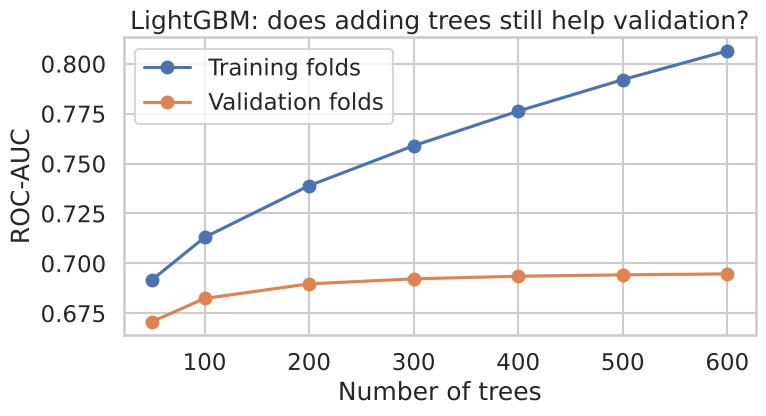

,train,val
trees,,
50,0.6918,0.6708
100,0.7130,0.6824
200,0.7389,0.6897
300,0.7589,0.6922
400,0.7763,0.6936
500,0.7920,0.6942
600,0.8065,0.6947


In [29]:
cv_curve = lgb_curves.groupby("trees")[["train", "val"]].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cv_curve.index, cv_curve.train, "o-", label="Training folds")
ax.plot(cv_curve.index, cv_curve.val, "o-", label="Validation folds")
ax.set(xlabel="Number of trees", ylabel="ROC-AUC", title="LightGBM: does adding trees still help validation?")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_lgbm_learning.png", dpi=200); plt.show()
cv_curve.round(4)

### 4.6b A more conservative LightGBM

The default LightGBM shows a large train–validation gap (≈0.11), yet validation AUC barely improves after ~400 trees: the extra trees mostly **memorise** the training data. That does not hurt validation here, but a model that memorises is more fragile when customer behaviour shifts. We test a simpler configuration: smaller trees (15 leaves), ≥300 customers per leaf, stronger L2 penalty (5.0), 800 trees.

In [30]:
def make_lgbm_reg():
    p = make_lgbm()
    p.set_params(model__num_leaves=15, model__min_child_samples=300, model__reg_lambda=5.0, model__n_estimators=800)
    return p

lgbr_folds, lgbr_oof, lgbr_curves = run_cv(make_lgbm_reg, LGBM_FIT, name="LightGBM-conservative",
                                           curve_iters=[200, 400, 600, 800])
key = ["train ROC-AUC", "val ROC-AUC", "val PR-AUC", "val F1@0.5", "val Precision top20%", "val Recall top20%", "val Lift top20%"]
final_cmp = pd.DataFrame({"Logistic Regression": lr_folds[key].mean(),
                          "LightGBM (default)": lgb_folds[key].mean(),
                          "LightGBM (conservative)": lgbr_folds[key].mean()})
final_cmp.loc["train−val AUC gap"] = final_cmp.loc["train ROC-AUC"] - final_cmp.loc["val ROC-AUC"]
final_cmp.loc["val ROC-AUC sd across folds"] = [lr_folds["val ROC-AUC"].std(), lgb_folds["val ROC-AUC"].std(), lgbr_folds["val ROC-AUC"].std()]
final_cmp.round(4)

LightGBM-conservative fold 1: train AUC 0.7608 | val AUC 0.6956


LightGBM-conservative fold 2: train AUC 0.7607 | val AUC 0.6910


LightGBM-conservative fold 3: train AUC 0.7620 | val AUC 0.6884


LightGBM-conservative fold 4: train AUC 0.7600 | val AUC 0.6996


LightGBM-conservative fold 5: train AUC 0.7609 | val AUC 0.6936


,Logistic Regression,LightGBM (default),LightGBM (conservative)
train ROC-AUC,0.6609,0.8065,0.7609
val ROC-AUC,0.6555,0.6947,0.6936
val PR-AUC,0.6380,0.6810,0.6787
val F1@0.5,0.6033,0.6385,0.6376
val Precision top20%,0.6836,0.7301,0.7289
val Recall top20%,0.2759,0.2946,0.2941
val Lift top20%,1.3793,1.4730,1.4707
train−val AUC gap,0.0054,0.1118,0.0672
val ROC-AUC sd across folds,0.0040,0.0047,0.0043


**Model selection (made on cross-validation only; test set still untouched).**
- Both LightGBM versions beat Logistic Regression in every fold (≈ +0.04 AUC, top-20% lift ≈ 1.47 vs 1.38).
- The two LightGBM versions differ by ≈0.001 AUC — well inside the fold-to-fold variation — but the conservative one has a much smaller train–validation gap.
- **When validation performance is equal, choose the simpler model.** Selected: **LightGBM (conservative)**. Logistic Regression is kept as the transparent benchmark and as a cross-check on the direction of key effects.

### 4.6c Final comparison charts (cross-validation, selected model)

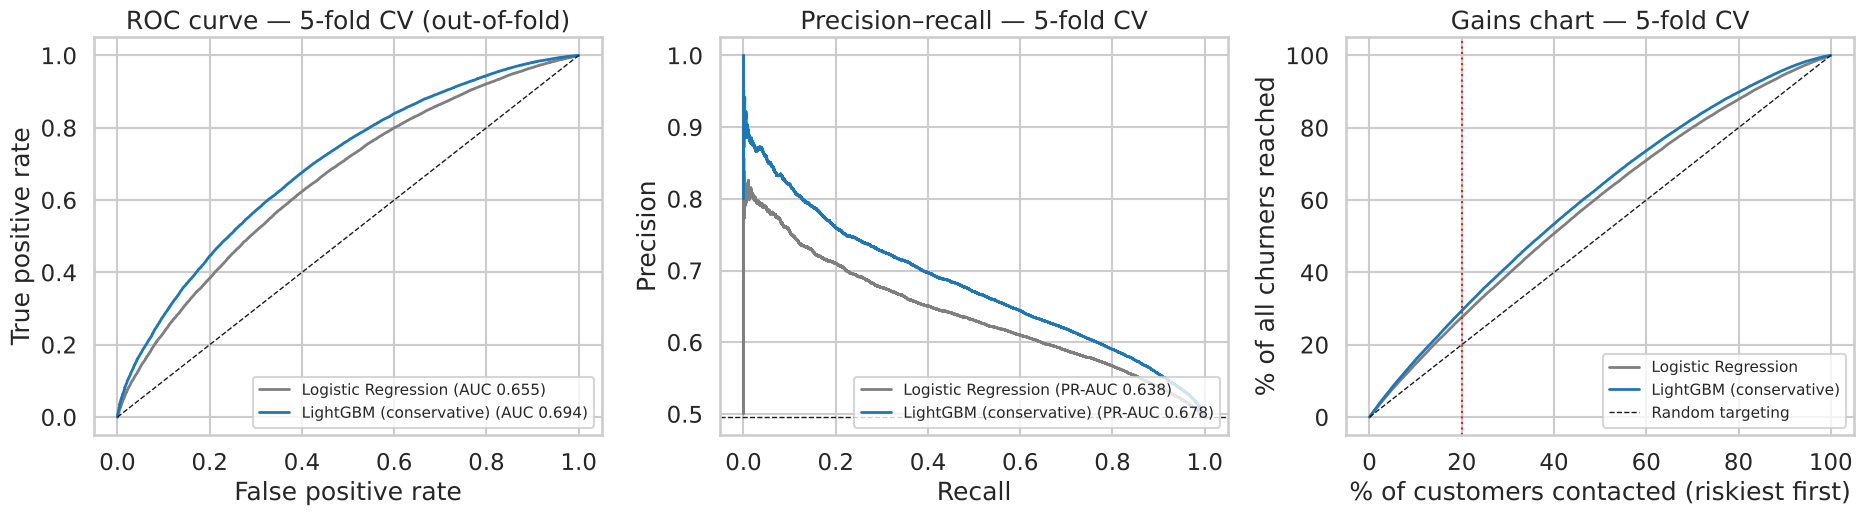

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for name, p, c in [("Logistic Regression", lr_oof, "#7f7f7f"), ("LightGBM (conservative)", lgbr_oof, "#1f77b4")]:
    fpr, tpr, _ = roc_curve(y_train, p)
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(y_train, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_train, p)
    axes[1].plot(rc, pr, color=c, lw=2, label=f"{name} (PR-AUC {average_precision_score(y_train, p):.3f})")
    order = np.argsort(-p); cum = np.cumsum(y_train.values[order]) / y_train.sum()
    axes[2].plot(np.arange(1, len(p) + 1) / len(p) * 100, cum * 100, color=c, lw=2, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve — 5-fold CV (out-of-fold)")
axes[1].axhline(y_train.mean(), color="k", ls="--", lw=1); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall — 5-fold CV")
axes[2].plot([0, 100], [0, 100], "k--", lw=1, label="Random targeting")
axes[2].axvline(20, color="#d62728", ls=":", lw=1.5)
axes[2].set(xlabel="% of customers contacted (riskiest first)", ylabel="% of all churners reached", title="Gains chart — 5-fold CV")
for a in axes: a.legend(fontsize=11, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_model_comparison.png", dpi=200); plt.show()

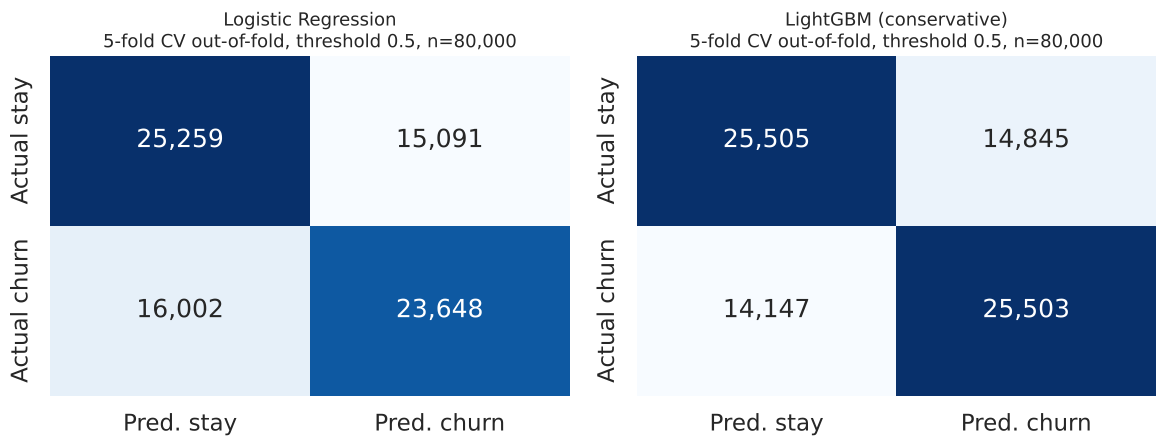

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, p) in zip(axes, [("Logistic Regression", lr_oof), ("LightGBM (conservative)", lgbr_oof)]):
    cm = confusion_matrix(y_train, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred. stay", "Pred. churn"], yticklabels=["Actual stay", "Actual churn"])
    ax.set_title(f"{name}\n5-fold CV out-of-fold, threshold 0.5, n={len(p):,}", fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_confusion.png", dpi=200); plt.show()

### 4.7 What precision would look like at a realistic churn rate

Precision depends on how common churners are. Using the true-positive and false-positive rates of the top-20% list (which do not depend on the base rate), we can recompute precision for lower churn rates. The rates below are **illustrative scenarios**, not Company A facts.

In [33]:
def precision_at_prevalence(y_true, p, prevalence, share=TOP_SHARE):
    y_true = np.asarray(y_true)
    thr = np.quantile(p, 1 - share)
    pred = p >= thr
    tpr = pred[y_true == 1].mean(); fpr = pred[y_true == 0].mean()
    return tpr * prevalence / (tpr * prevalence + fpr * (1 - prevalence))

rows = []
for prev in [0.496, 0.10, 0.05, 0.02]:
    rows.append({"assumed churn rate": prev,
                 "LogReg precision (top20% rule)": precision_at_prevalence(y_train, lr_oof, prev),
                 "LightGBM-cons. precision (top20% rule)": precision_at_prevalence(y_train, lgbr_oof, prev),
                 "random targeting precision": prev})
pd.DataFrame(rows).round(3)

,assumed churn rate,LogReg precision (top20% rule),LightGBM-cons. precision (top20% rule),random targeting precision
0,0.496,0.684,0.729,0.496
1,0.100,0.196,0.233,0.100
2,0.050,0.104,0.126,0.050
3,0.020,0.043,0.053,0.020


**Status.** Model comparison complete on cross-validation. The test set is still untouched. Interpretation of these results and the final model choice follow after review.

### 4.8 Final model choice and limitations (decided on cross-validation only)

**Selected model: LightGBM (conservative).**
- Beats Logistic Regression in all 5 folds (CV ROC-AUC ≈ 0.694 vs 0.656; top-20% lift ≈ 1.47 vs 1.38).
- Same validation performance as the default LightGBM, but about half the train–validation gap → less memorisation, more robust to change.

**Limitations.**
- **Moderate discrimination** (AUC ≈ 0.69). Good for *ranking* customers, not for confident individual predictions.
- **Random, not time-based, validation**: there is no date column, so performance on a *future* period is untested. Behaviour drifts; production use needs out-of-time monitoring.
- **Sample churn ≈ 50%** by design: probabilities are calibrated to this sample, not to Company A's real churn rate. Rankings remain valid; absolute probabilities and precision do not transfer (Section 4.7).
- **Predictive, not causal**: the model says *who is likely to leave*, not *what would make them stay*.

**Decisions locked before using the test set:** feature set (Section 3), preprocessing (Section 4.2), model and hyperparameters (Section 4.6b), metrics and the 20% illustrative contact list. Nothing below changes them.

## 5. Test-set evaluation (used once)

The selected pipeline is refitted on all 80,000 training customers and scored **once** on the 20,000 held-out customers. These are the numbers to quote as "expected performance on new customers from the same population".

In [34]:
final_model = make_lgbm_reg()
final_model.fit(X_train, y_train, **LGBM_FIT)
p_test = final_model.predict_proba(X_test)[:, 1]

test_m = all_metrics(y_test, p_test)
cv_m = {k.replace("val ", ""): v for k, v in lgbr_folds.drop(columns="fold").mean().items() if k.startswith("val ")}
cv_sd = {k.replace("val ", ""): v for k, v in lgbr_folds.drop(columns="fold").std().items() if k.startswith("val ")}
test_table = pd.DataFrame({"5-fold CV mean (train set)": cv_m, "CV sd": cv_sd, "TEST set (20,000)": test_m})
test_table["Test − CV"] = test_table["TEST set (20,000)"] - test_table["5-fold CV mean (train set)"]
test_table.round(4)

,5-fold CV mean (train set),CV sd,"TEST set (20,000)",Test − CV
ROC-AUC,0.6936,0.0043,0.6949,0.0012
PR-AUC,0.6787,0.0065,0.6829,0.0042
Precision@0.5,0.6321,0.0036,0.6330,0.0009
Recall@0.5,0.6432,0.0047,0.6441,0.0009
F1@0.5,0.6376,0.0022,0.6385,0.0009
Accuracy@0.5,0.6376,0.0026,0.6385,0.0010
Precision top20%,0.7289,0.0109,0.7382,0.0093
Recall top20%,0.2941,0.0044,0.2979,0.0038
Lift top20%,1.4707,0.0220,1.4896,0.0189


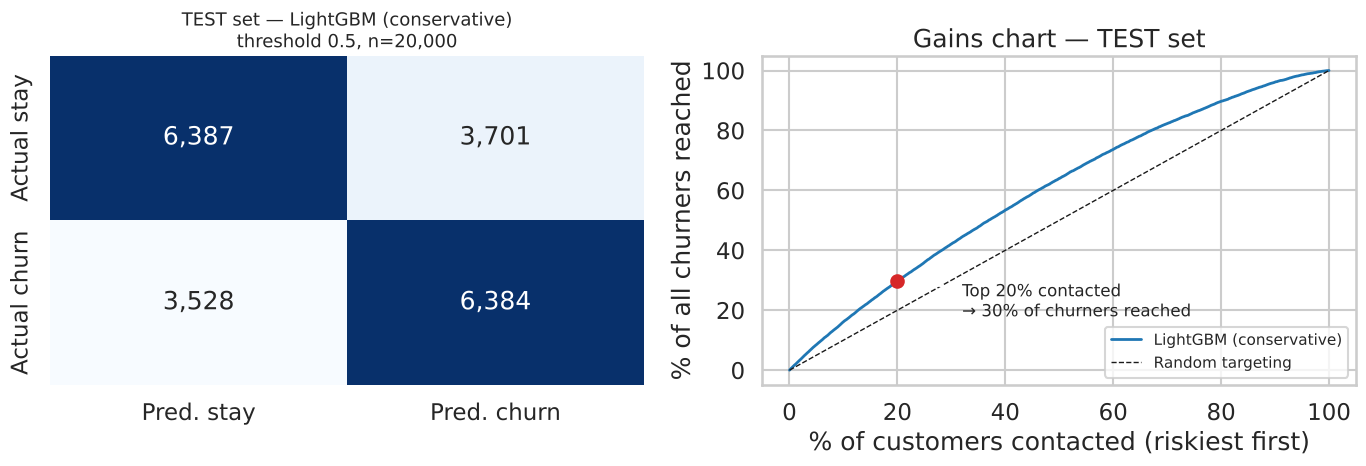

In [35]:
cm_test = confusion_matrix(y_test, (p_test >= 0.5).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_test, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred. stay", "Pred. churn"], yticklabels=["Actual stay", "Actual churn"])
axes[0].set_title("TEST set — LightGBM (conservative)\nthreshold 0.5, n=20,000", fontsize=13)

order = np.argsort(-p_test)
cum = np.cumsum(y_test.values[order]) / y_test.sum()
x = np.arange(1, len(order) + 1) / len(order) * 100
axes[1].plot(x, cum * 100, lw=2, color="#1f77b4", label="LightGBM (conservative)")
axes[1].plot([0, 100], [0, 100], "k--", lw=1, label="Random targeting")
k20 = int(0.2 * len(order))
axes[1].scatter([20], [cum[k20 - 1] * 100], color="#d62728", zorder=5)
axes[1].annotate(f"Top 20% contacted\n→ {cum[k20-1]*100:.0f}% of churners reached", (20, cum[k20 - 1] * 100),
                 xytext=(32, 18), fontsize=12, arrowprops=dict(arrowstyle="->"))
axes[1].set(xlabel="% of customers contacted (riskiest first)", ylabel="% of all churners reached",
            title="Gains chart — TEST set")
axes[1].legend(loc="lower right", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig8_test_results.png", dpi=200); plt.show()

In [36]:
# Decile view: actual churn rate and revenue by predicted-risk decile (TEST set)
test_df = X_test.copy()
test_df["churn"] = y_test.values
test_df["p_churn"] = p_test
test_df["risk_decile"] = pd.qcut(test_df.p_churn.rank(method="first", ascending=False), 10, labels=range(1, 11))
dec = test_df.groupby("risk_decile", observed=True).agg(customers=("churn", "size"), actual_churn=("churn", "mean"),
                                                        mean_pred=("p_churn", "mean"), mean_monthly_rev=("rev_Mean", "mean"))
dec["lift"] = dec.actual_churn / test_df.churn.mean()
dec.round(3)

,customers,actual_churn,mean_pred,mean_monthly_rev,lift
risk_decile,,,,,
1,2000,0.800,0.775,53.672,1.615
2,2000,0.676,0.669,59.316,1.364
3,2000,0.610,0.612,59.320,1.232
4,2000,0.559,0.566,57.791,1.128
5,2000,0.524,0.523,55.752,1.058
6,2000,0.481,0.480,57.299,0.971
7,2000,0.427,0.435,60.376,0.862
8,2000,0.368,0.382,61.515,0.742
9,2000,0.319,0.313,64.379,0.644


**How to read the test results.** If the test scores are close to the cross-validation means (within a few fold standard deviations), the CV estimate was reliable and the model did not overfit the training set. The decile table shows the model's main business value: actual churn falls steadily from the highest-risk decile to the lowest, so working down the list concentrates effort where churn is most likely.

## 6. Business interpretation with SHAP

**What SHAP does.** For each customer, SHAP splits the model's prediction into contributions from each feature: "this customer's risk is above average *because* their handset is 2 years old (+), they are in month 11 (+), and they use many minutes (−)". Averaging the size of these contributions across customers gives global importance.

> **Predictive, not causal.** SHAP explains *what the model uses*, not *what causes churn*. A feature can be important because it is a proxy for something else. Only an experiment can show whether changing a feature (e.g. giving a new handset) changes behaviour.

SHAP values here are on the **log-odds** scale (positive = pushes towards churn). Computed on the test set.

In [37]:
import shap
pre_final = final_model[:-1]
lgbm_final = final_model[-1]
Xt_test = pre_final.transform(X_test)
explainer = shap.TreeExplainer(lgbm_final)
shap_values = explainer(Xt_test)
if shap_values.values.ndim == 3:            # some versions return both classes
    shap_values = shap_values[:, :, 1]

NICE = {"eqpdays": "Handset age (days)", "eqp_years": "Handset age (years)", "months": "Tenure (months)",
        "hnd_price": "Handset price", "in_risk_window": "In months 10–12", "handset_vs_tenure": "Handset age ÷ tenure",
        "change_mou": "Change in minutes vs 3-mo avg", "mou_Mean": "Monthly minutes", "rev_Mean": "Monthly revenue",
        "totmrc_Mean": "Monthly recurring charge", "crclscod": "Credit class", "area": "Geographic area",
        "avgqty": "Avg monthly calls (lifetime)", "avgmou": "Avg monthly minutes (lifetime)", "avg3mou": "Avg minutes (last 3 mo)",
        "avg3qty": "Avg calls (last 3 mo)", "avgrev": "Avg monthly revenue (lifetime)", "drop_rate": "Dropped/blocked call rate",
        "rev_per_min": "Revenue per minute", "zero_usage": "Zero usage", "uniqsubs": "Subscribers in household",
        "actvsubs": "Active subscribers", "custcare_Mean": "Care calls", "adjmou": "Lifetime minutes (adj.)",
        "totmou": "Lifetime minutes", "adjqty": "Lifetime calls (adj.)", "totcalls": "Lifetime calls",
        "avg6mou": "Avg minutes (last 6 mo)", "avg6qty": "Avg calls (last 6 mo)", "change_rev": "Change in revenue vs 3-mo avg",
        "hnd_webcap": "Handset web capability", "asl_flag": "Spending limit", "ovrmou_Mean": "Overage minutes",
        "prizm_social_one": "Social group", "income": "Estimated income", "refurb_new": "Refurbished handset",
        "phones": "Handsets issued", "models": "Models issued", "adjrev": "Lifetime revenue (adj.)", "totrev": "Lifetime revenue",
        "mou_cvce_Mean": "Minutes, completed voice", "mou_opkv_Mean": "Off-peak voice minutes", "attempt_Mean": "Calls attempted",
        "complete_Mean": "Calls completed", "inonemin_Mean": "Inbound calls < 1 min", "lor": "Length of residence", "drop_vce_Mean": "Dropped voice calls"}
shap_values.feature_names = [NICE.get(c, c) for c in Xt_test.columns]

imp = pd.Series(np.abs(shap_values.values).mean(0), index=Xt_test.columns).sort_values(ascending=False)
imp_df = imp.head(15).to_frame("mean |SHAP|"); imp_df.index = [NICE.get(i, i) for i in imp_df.index]
imp_df.round(4)

,mean |SHAP|
Handset age (days),0.1750
Change in minutes vs 3-mo avg,0.1596
Tenure (months),0.1578
Revenue per minute,0.1379
Credit class,0.0922
Monthly recurring charge,0.0886
Subscribers in household,0.0861
Monthly minutes,0.0823
Handset price,0.0777
Avg monthly calls (lifetime),0.0762


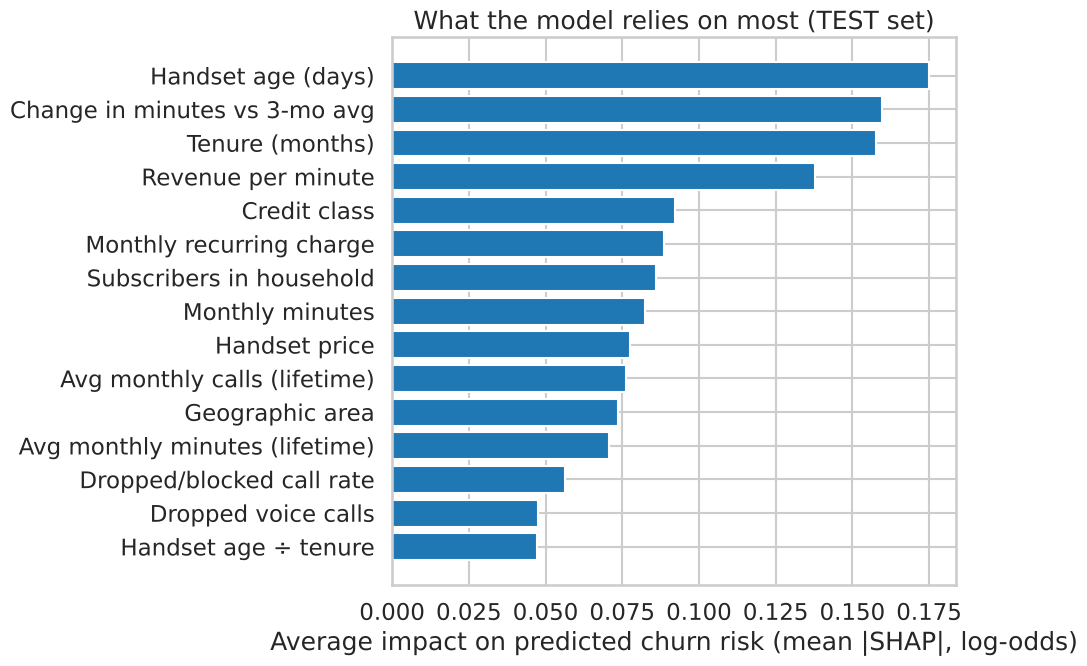

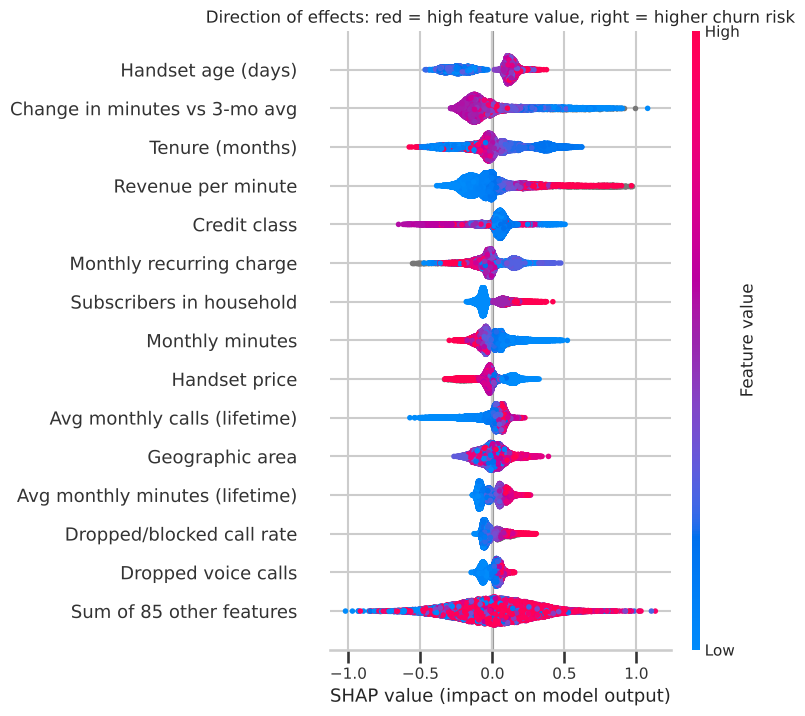

In [38]:
fig, ax = plt.subplots(figsize=(10, 7))
top = imp_df.iloc[::-1]
ax.barh(top.index, top["mean |SHAP|"], color="#1f77b4")
ax.set_xlabel("Average impact on predicted churn risk (mean |SHAP|, log-odds)")
ax.set_title("What the model relies on most (TEST set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig9_shap_importance.png", dpi=200); plt.show()

plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("Direction of effects: red = high feature value, right = higher churn risk", fontsize=12)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig10_shap_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

**Does the model confirm the validated hypotheses?** Two dependence plots: how tenure and handset age push predicted risk. If the model has independently learned the month-11 step and the handset-age gradient, the earlier statistical findings and the ML model tell the same story.

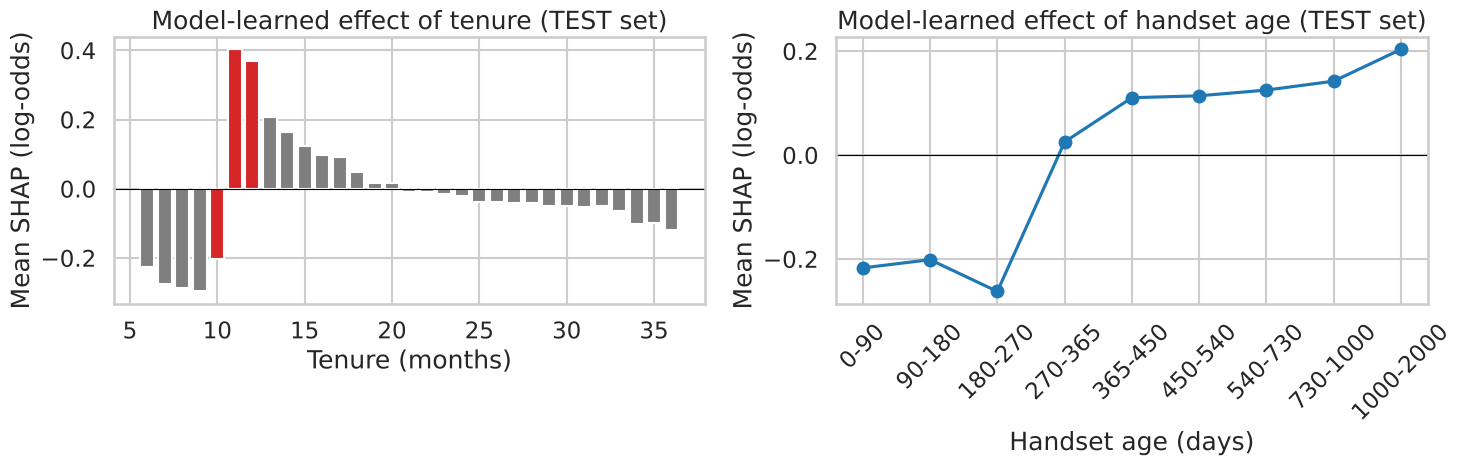

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cols = list(Xt_test.columns)
i_m, i_e = cols.index("months"), cols.index("eqpdays")
sm = pd.DataFrame({"months": Xt_test["months"].values, "shap": shap_values.values[:, i_m]})
sm = sm[sm.months <= 36].groupby("months").shap.mean()
axes[0].bar(sm.index, sm.values, color=["#d62728" if m in (10, 11, 12) else "#7f7f7f" for m in sm.index])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="Tenure (months)", ylabel="Mean SHAP (log-odds)", title="Model-learned effect of tenure (TEST set)")
se = pd.DataFrame({"eqp": Xt_test["eqpdays"].values, "shap": shap_values.values[:, i_e]}).dropna()
se["bin"] = pd.cut(se.eqp, [0, 90, 180, 270, 365, 450, 540, 730, 1000, 2000])
sb = se.groupby("bin", observed=True).shap.mean()
axes[1].plot(range(len(sb)), sb.values, "o-", color="#1f77b4")
axes[1].set_xticks(range(len(sb))); axes[1].set_xticklabels([f"{int(b.left)}-{int(b.right)}" for b in sb.index], rotation=45)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="Handset age (days)", ylabel="Mean SHAP (log-odds)", title="Model-learned effect of handset age (TEST set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig11_shap_dependence.png", dpi=200); plt.show()

### 6.1 Explaining individual customers

Two real test-set customers among the top 5% risk **with above-median monthly revenue and active usage** (customers worth assessing; zero-usage customers are excluded because they belong to the "likely already gone" group): one inside the months 10–12 window, one long-tenure customer with an old handset. The waterfall starts from the average prediction and shows which features push this customer's risk up (red) or down (blue).

A: in months 10–12: predicted 0.90 | actual churn 1 | tenure 11 mo | handset 326 days | revenue $52/mo


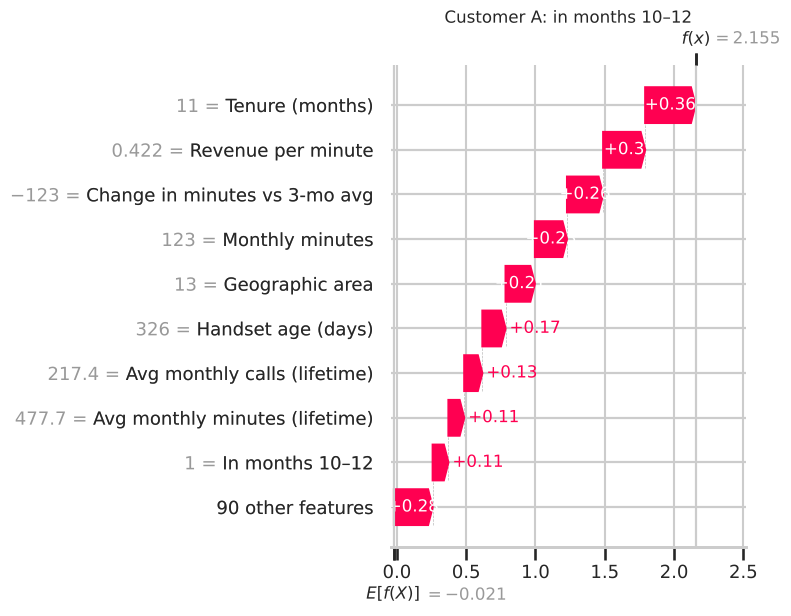

B: long tenure, old handset: predicted 0.90 | actual churn 1 | tenure 28 mo | handset 833 days | revenue $51/mo


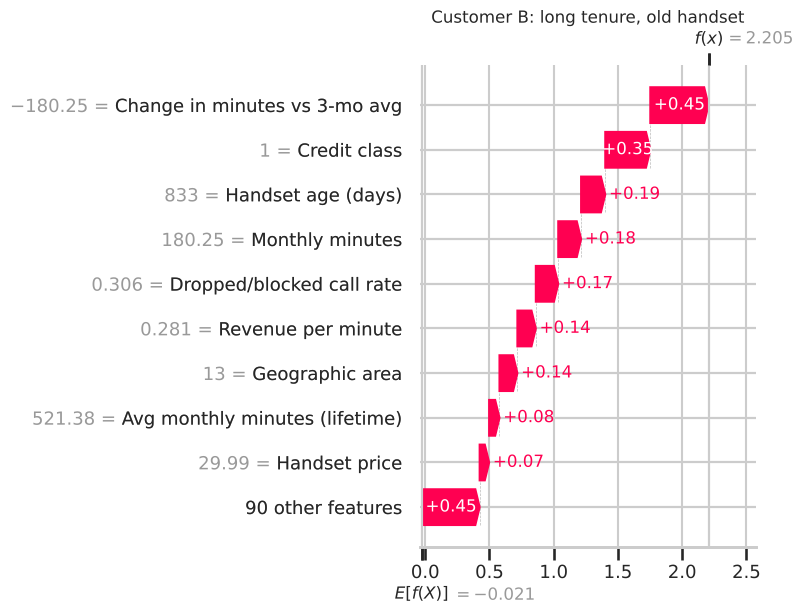

In [40]:
top5 = test_df.p_churn >= test_df.p_churn.quantile(0.95)
pos = {cid: i for i, cid in enumerate(X_test.index)}
rev_med = X_train.rev_Mean.median()   # median from TRAIN data
hv = (test_df.rev_Mean >= rev_med) & (test_df.zero_usage == 0) & (test_df.usage_missing == 0)   # active, above-median value
cand_a = test_df[top5 & hv & (test_df.months.between(10, 12))].sort_values("p_churn", ascending=False)
cand_b = test_df[top5 & hv & (test_df.months >= 24) & (test_df.eqpdays >= 540)].sort_values("p_churn", ascending=False)
examples = {"A: in months 10–12": cand_a.index[0], "B: long tenure, old handset": cand_b.index[0]}
for label, idx in examples.items():
    r = test_df.loc[idx]
    print(f"{label}: predicted {r.p_churn:.2f} | actual churn {int(r.churn)} | tenure {int(r.months)} mo | "
          f"handset {r.eqpdays:.0f} days | revenue ${r.rev_Mean:.0f}/mo")
    plt.figure()
    shap.plots.waterfall(shap_values[pos[idx]], max_display=10, show=False)
    plt.title(f"Customer {label}", fontsize=12)
    fname = "fig12a_waterfall.png" if label.startswith("A") else "fig12b_waterfall.png"
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=200, bbox_inches="tight"); plt.show()

### 6.2 From scores to actionable segments

A risk score alone does not say *what to do*. We combine the score with the strongest **actionable** signals to suggest which kind of assessment each high-risk customer should get. Segments are rule-based and assigned in priority order (each customer gets one). They describe the **top 20% predicted risk** on the test set.

| Segment | Rule | Possible action to *test* |
|---|---|---|
| Data-quality review | monthly-usage block missing (`usage_missing`) | **Not** treated as inactive (Section 3.7.3 showed normal recent revenue and long tenure). Fix the data first, then re-score |
| Likely inactive | billed but **zero** minutes of use (`zero_usage`) | Low-cost win-back check; don't spend heavily |
| Renewal window | tenure 9–12 months | Pre-renewal outreach (month 9–10) |
| Ageing handset | handset ≥ 365 days | Upgrade offer tied to a new commitment |
| Service quality | dropped/blocked rate in top 25% | Network fix / service credit — not a discount |
| Other high risk | none of the above | Investigate; general retention |

> **Correction.** An earlier version grouped missing-usage customers with zero-usage customers as "likely already gone". That contradicted Section 3.7.3: missing usage looks like a data-extraction gap, not inactivity. They now form a separate **data-quality review** segment and are never classified as inactive.

In [41]:
q_drop = X_train["drop_rate"].quantile(0.75)        # threshold from TRAIN data only
hi = test_df[test_df.p_churn >= test_df.p_churn.quantile(0.80)].copy()   # top 20% OF THE BALANCED TEST SAMPLE

def segment(r):
    if r.usage_missing == 1:   return "1 Data-quality review"   # data gap, NOT inactivity
    if r.zero_usage == 1:      return "2 Likely inactive"       # observed zero minutes
    if 9 <= r.months <= 12:    return "3 Renewal window"
    if r.eqpdays >= 365:       return "4 Ageing handset"
    if r.drop_rate >= q_drop:  return "5 Service quality"
    return "6 Other high risk"

hi["segment"] = hi.apply(segment, axis=1)
hi["value_rev"] = hi.rev_Mean.fillna(hi.avg3rev)   # missing-usage block: use 3-month revenue from Client table
seg = hi.groupby("segment").agg(customers=("churn", "size"), actual_churn=("churn", "mean"),
                                mean_pred=("p_churn", "mean"), mean_monthly_rev=("value_rev", "mean"),
                                total_monthly_rev=("value_rev", "sum"))
seg["share_of_top20"] = seg.customers / len(hi)
display(seg.round(3))
print(f"Top-20% list: {len(hi):,} customers | actual churn {hi.churn.mean():.3f} vs test average {test_df.churn.mean():.3f}")
print(f"Dropped-call threshold (75th pct, train): {q_drop:.3f}")
assert not ((hi.usage_missing == 1) & hi.segment.str.contains("inactive")).any(), "missing-usage customer classified as inactive"
print("Check passed: no missing-usage customer is classified as inactive.")

,customers,actual_churn,mean_pred,mean_monthly_rev,total_monthly_rev,share_of_top20
segment,,,,,,
1 Data-quality review,40,0.825,0.828,65.125,2605.000,0.010
2 Likely inactive,281,0.836,0.826,24.272,6820.361,0.070
3 Renewal window,1352,0.759,0.717,60.316,81546.938,0.338
4 Ageing handset,1906,0.711,0.712,53.244,101483.230,0.476
5 Service quality,133,0.782,0.715,73.906,9829.438,0.033
6 Other high risk,288,0.694,0.699,83.698,24105.018,0.072


Top-20% list: 4,000 customers | actual churn 0.738 vs test average 0.496
Dropped-call threshold (75th pct, train): 0.089
Check passed: no missing-usage customer is classified as inactive.


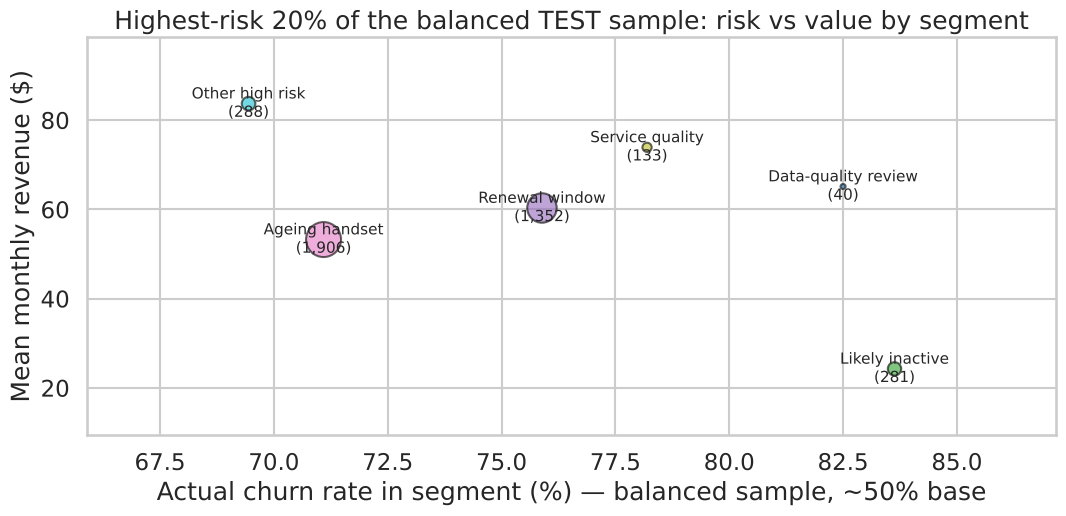

In [42]:
fig, ax = plt.subplots(figsize=(11, 5.5))
s = seg.reset_index()
s["label"] = s.segment.str[2:]
sc = ax.scatter(s.actual_churn * 100, s.mean_monthly_rev, s=s.customers / 3, alpha=0.6,
                c=range(len(s)), cmap="tab10", edgecolor="black")
for _, r in s.iterrows():
    ax.annotate(f"{r.label}\n({r.customers:,})", (r.actual_churn * 100, r.mean_monthly_rev),
                ha="center", va="center", fontsize=11)
ax.set(xlabel="Actual churn rate in segment (%) — balanced sample, ~50% base", ylabel="Mean monthly revenue ($)",
       title="Highest-risk 20% of the balanced TEST sample: risk vs value by segment")
ax.margins(0.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig13_segments.png", dpi=200); plt.show()

**How the predictions support retention decisions.**
1. **Score** every customer monthly; work down the ranked list as far as the budget allows.
2. **Route** each high-risk customer to a segment-appropriate action, not a blanket discount.
3. **Weigh value against cost**: a customer's expected benefit ≈ churn risk × value × chance the offer changes the decision − offer cost. The last factor (*uplift*) is unknown from observational data.
4. **Test before scaling**: randomly hold out part of each segment as a control group, so the effect of each action can be measured (validation plan, next stage).

What the model **cannot** tell us: whether an offer will change anyone's decision. Customers with a high score may leave regardless (e.g. "likely already gone"), and some will stay anyway.

## 7. Industry benchmarks and churn scenarios

**Why this is needed.** The dataset's 49.6% churn rate is a sampling choice, not Company A's reality. Any financial estimate must use a realistic churn rate. Company A's label measures churn **within one 30-day window** (days 31–60 after T), so **monthly churn rates** are the matching unit.

**What kind of operator is Company A? (from the data, not assumed)** Credit class codes, account spending limits, subsidised handsets (`hnd_price`, refurbished vs new) and a sharp risk step after ~11 months all point to a **contract (postpaid) mobile operator**. The data does not reveal the country or time period.

### 7.1 External benchmarks

| # | Organisation & source | Published | Market | Churn definition | Value | Comparable to Company A? |
|---|---|---|---|---|---|---|
| B1 | Verizon, Q3 2026 earnings release (Form 8-K, Exhibit 99) | Oct 2026 | US, national postpaid | Postpaid **phone** churn, monthly (disconnections ÷ average connections per month) | 0.94% (consumer: 0.87%) | Partly: same contract model, but a mature, low-churn market leader today |
| B2 | T-Mobile US, Q4 & FY2025 results release | Jan 2026 | US, national | Postpaid phone churn, monthly; **prepaid** churn, monthly | Postpaid phone 0.93% (FY2025); prepaid 2.72% (FY2025) | Postpaid: partly (as B1). Prepaid: **not** comparable (Company A appears contract-based) — used only as an upper bound |
| B3 | T-Mobile US, Form 10-Q Q3 2026 | Oct 2026 | US, national | Postpaid **account** churn = deactivated accounts ÷ average accounts ÷ months in period | 1.09% (Q3 2026) | Weak: includes broadband-only accounts; shown to illustrate how definitions differ |
| B4 | Lemmens & Croux, *Journal of Marketing Research* 43(2), 276–286 | 2006 | US wireless: a major US carrier's subscriber data (Duke/NCR Teradata churn tournament) | Carrier's **reported average monthly churn**; industry monthly churn (citing Hawley 2003) | **≈ 1.8%** carrier; ≈ 2.6% industry | **Strongest match**: same sampling design as Company A's data — subscribers with ≥ 6 months tenure, churn measured 31–60 days after the snapshot, a balanced ~100,000-customer sample, and the same variable families. Old (early 2000s) and not necessarily the same company |

Sources:
- B1: https://www.sec.gov/Archives/edgar/data/0000732712/000073271226000049/a2026q3exhibit99.htm
- B2: https://quantisnow.com/insight/t-mobile-delivers-best-in-class-customer-results-in-q4-translating-into-durable-6385633 (reproduction of T-Mobile's press release)
- B3: https://www.sec.gov/Archives/edgar/data/0001283699/000128369926000129/tmus-20260930.htm
- B4: https://scispace.com/pdf/bagging-and-boosting-classification-trees-to-predict-churn-boq2zc7149.pdf (author version, Tilburg University repository copy)

**What the benchmarks do and don't tell us.** Today's largest US contract operators lose about **1% of phone customers per month**; a US carrier whose data used the *same sampling design as Company A's* reported **~1.8%**; the contract-era industry average was **~2.6%**; prepaid customers churn at **~2.7%**. The same study also found churn risk rising sharply in a handset's first year, which it linked to one-year subscription plus free-handset packages — independent support for our renewal-window interpretation. Company A's features (subsidised handsets, credit classes, web-capable vs basic handsets) resemble a contract operator in a competitive market, but its country and era are unknown, so no single benchmark can be treated as Company A's actual rate. The benchmarks define a **plausible range**, not a fact.

### 7.2 Three clearly separated layers

| Layer | Item | Value | Source |
|---|---|---|---|
| **Dataset finding** | Mean monthly revenue per customer | computed below | `rev_Mean`, Company A data |
| **Dataset finding** | Score-threshold list (cut-off = top 20% of the *balanced* test sample): true- and false-positive rates | computed below (test set) | Section 5 |
| **External benchmark** | Monthly churn, contract operators | 0.9–1.1% today; ~2–2.6% contract era | B1–B4 |
| **Assumption** | Company A real monthly churn — LOW | **1.0%** | Anchored on B1/B2 postpaid |
| **Assumption** | Company A real monthly churn — MEDIUM (central case) | **2.0%** | Anchored on B4: 1.8% for a carrier with the same data design, rounded up |
| **Assumption** | Company A real monthly churn — HIGH | **2.7%** | Upper bound anchored on B2 prepaid / B4 industry |
| **Assumption** | Customer base for illustration | 100,000 (same size as the dataset) | Scale only; results are linear in base size |

Not yet assumed (to be agreed before the financial model): gross margin on revenue, offer cost, offer acceptance rate, and — most uncertain — the **share of contacted would-be churners whose decision the offer actually changes**.

In [43]:
mean_rev = df.rev_Mean.mean()
median_rev = df.rev_Mean.median()

thr20 = np.quantile(p_test, 0.8)
flag = p_test >= thr20
tpr20 = flag[y_test.values == 1].mean()        # recall of churners in top-20% list (base-rate independent)
fpr20 = flag[y_test.values == 0].mean()        # share of stayers wrongly included

print(f"DATASET  mean monthly revenue: ${mean_rev:.2f} | median: ${median_rev:.2f}")
print(f"DATASET  top-20% list (test): TPR {tpr20:.3f}, FPR {fpr20:.3f}")

BASE = 100_000
scen = pd.DataFrame({"scenario": ["LOW", "MEDIUM (central)", "HIGH"], "monthly churn (assumption)": [0.010, 0.020, 0.027]})
rows = []
for _, r in scen.iterrows():
    c = r["monthly churn (assumption)"]
    churners = BASE * c
    flagged_churners = churners * tpr20
    flagged_stayers = BASE * (1 - c) * fpr20
    list_size = flagged_churners + flagged_stayers
    rows.append({**r,
                 "expected churners / month": churners,
                 "monthly revenue lost to churn ($)": churners * mean_rev,
                 "score-threshold list size": list_size,
                 "churners on list": flagged_churners,
                 "precision of list": flagged_churners / list_size,
                 "random-list precision": c,
                 "revenue of churners on list ($/mo)": flagged_churners * mean_rev})
scen_df = pd.DataFrame(rows)
scen_df.round(3)

DATASET  mean monthly revenue: $58.72 | median: $48.20
DATASET  top-20% list (test): TPR 0.298, FPR 0.104


,scenario,monthly churn (assumption),expected churners / month,monthly revenue lost to churn ($),score-threshold list size,churners on list,precision of list,random-list precision,revenue of churners on list ($/mo)
0,LOW,0.010,1000.0,58719.985,10572.803,297.922,0.028,0.010,17493.958
1,MEDIUM (central),0.020,2000.0,117439.970,10766.938,595.843,0.055,0.020,34987.917
2,HIGH,0.027,2700.0,158543.959,10902.832,804.389,0.074,0.027,47233.688


**Reading the scenarios.**
- In every scenario the model's list is **about 2.7–2.8× more concentrated in churners** than a random list (e.g. 5.5% vs 2.0% in the central case). This is larger than the 1.49× lift seen in the 50% sample, because in a 50% sample lift can never exceed 2×; at realistic churn rates the same ranking quality (TPR 0.298 vs FPR 0.104) produces a bigger relative gain.
- **Naming matters.** The cut-off that selects the riskiest 20% of the *balanced sample* selects only about **11% of a realistic customer base**, because a real base is mostly low-risk stayers. We therefore call it the **score-threshold list**, not "the top 20%".
- But in absolute terms most contacted customers would **not** churn: at a 2% monthly churn rate, only a few percent of the list are real would-be churners. An offer given to everyone on the list is therefore paid mostly to customers who would have stayed. This is why the next stage must (a) keep the offer cheap or value-targeted, and (b) measure real uplift with a control group.
- The revenue figures use the **sample's** mean revenue and assume churners' revenue is typical; they describe *revenue exposed*, not profit saved.

**Method.** The realistic population is simulated by re-weighting the test set: churners and stayers keep their scores but are weighted so that churners make up 1%, 2% or 2.7% of the base. True- and false-positive rates (which do not depend on the churn rate) carry over.

### 7.3 What deployment would need before building a real "top 20%" list

1. **Rank the real customer base, not the sample.** A real top-20% list is simply the 20% of *current* customers with the highest scores. Ranking does not need calibrated probabilities, but the list's *composition* (how many real churners it holds) must be estimated on real data.
2. **Re-calibrate probabilities to the real churn rate.** The model learned on a 50% sample, so its probabilities are inflated. A prior-shift correction (multiply the odds by the ratio of real to sample churn odds) is a first step; it must then be checked with a calibration curve on a recent, *unbalanced* sample of customers.
3. **Out-of-time validation.** Score customers at one date, observe who churns 31–60 days later, and confirm ranking quality (AUC, lift) and calibration hold on that later period.
4. **Confirm the churn rate itself.** Replace our benchmark-based 1–2.7% scenarios with Company A's actual monthly churn.
5. **Monitor drift monthly** and retrain when performance drops.

## 8. Financial model: break-even analysis

**The central question is not "how much money will we make?" but "what would have to be true for a retention programme to pay for itself?"** The model predicts *who is likely to churn* (risk). It does **not** predict *who can be persuaded to stay* (treatment response, or **uplift**). Uplift can only be measured with a randomised controlled pilot, so the financial model is built around the **break-even uplift**: the minimum effect the pilot must demonstrate before the programme is scaled.

All calculations are **per monthly campaign cycle** on a customer base of 100,000 (the dataset's size; results scale linearly). We do not multiply by 12: the same customers can be flagged again next month, and annualising would double-count them.

### 8.1 Assumptions — three separate layers

**A. Dataset findings (Company A data)**

| Item | Value | Where |
|---|---|---|
| Monthly revenue of each flagged customer | individual `rev_Mean` (3-month revenue `avg3rev` used for the missing-usage block) | Test set |
| Ranking quality (true/false-positive rates at each cut-off) | from the selected model | Test set, Section 5 |

**B. External benchmarks**

| Item | Value | Source | Comparability |
|---|---|---|---|
| Monthly churn | 0.9–1.1% (US postpaid today); ~2–2.6% (US contract era) | Section 7 (B1–B4) | Range only |
| Margin: Verizon Consumer segment **operating-income** margin | 30.6% (Q3 2026) | Verizon Q3 2026 Form 8-K, Exh. 99 [M1] | After depreciation: a conservative floor for the margin on one more month of a customer |
| Margin: Verizon Consumer segment **EBITDA** margin | 45.3% (Q3 2026) | Verizon Q3 2026 Form 8-K, Exh. 99 [M1] | Includes low-margin equipment sales; reasonable central proxy |
| Margin: T-Mobile **Core Adjusted EBITDA ÷ service revenue** | 48% (FY2025) | T-Mobile FY2025 Form 10-K [M2] | Service-revenue basis, close to Company A's `rev_Mean` (a monthly charge amount) |
| Retention incentives, US wireless | service credits $35–60; equipment credits $50–100; high-end average $60–100 per customer, usually tied to contract extensions and "recovered within a few months of contract renewal"; ARPU then $50–70 | RBC Capital Markets survey, reported by RCR Wireless, Aug 2003 [O1] | Strong era/business-model match (contract wireless, ARPU close to Company A's $58.7); old, US only |

Sources:
- [M1] https://www.sec.gov/Archives/edgar/data/0000732712/000073271226000049/a2026q3exhibit99.htm
- [M2] https://www.sec.gov/Archives/edgar/data/1283699/000128369926000010/tmus-20251231.htm
- [O1] https://rcrwireless.com/20030818/archived-articles/carriers-step-up-retention-efforts

**C. Assumptions (ours — to be replaced by Company A's own figures and the pilot)**

| Parameter | LOW | MEDIUM | HIGH | Basis |
|---|---|---|---|---|
| Real monthly churn `c` | 1.0% | 2.0% | 2.7% | Anchored on B1–B4 |
| Contribution margin `m` | 30% | 45% | 55% | Low/medium from M1; high **assumed** above EBITDA margin because one extra retained customer barely changes fixed network costs (no source) |
| Offer cost per accepted offer `o` | $35 | $60 | $100 | O1 range |
| Contact cost per contacted customer `k` | $1 | $2 | $5 | **Illustrative** (no reliable source) |
| Acceptance rate `a` | 30% | 50% | 70% | **Illustrative** (no reliable source) |
| Uplift `u` | 5% | 10% | 20% | **Illustrative**; to be measured by the pilot |
| Value horizon `H` | 6 months | 12 months | 24 months | **Illustrative**: how long a saved customer's margin is counted |

### 8.2 Formulas in plain English

For a contact list chosen by the model:

| Quantity | Formula | Meaning |
|---|---|---|
| List size `L` | weighted count of customers on the list | How many customers we contact |
| Would-be churners on list `C` | weighted count of actual churners on the list | Customers who *would* leave without any action |
| Months of margin kept per saved customer `H_eff` | `1 + (1−c) + (1−c)² + … ` for `H` months | A saved customer can still leave later at the normal churn rate, so 12 months of "possible" margin are worth slightly less than 12 |
| Value of one saved customer `V` | average revenue of the would-be churners on the list × `m` × `H_eff` | **Contribution profit**, not revenue |
| Incremental customers retained | `C × u` | **Uplift `u`** = share of would-be churners who stay *because of* the programme |
| Benefit `B` | `C × u × V` | Profit protected |
| Cost `K` | `L × k + L × a × o` | Everyone on the list is contacted; only those who **accept** cost the offer |
| Net benefit | `B − K` | |
| ROI | `(B − K) / K` | Return per $1 spent |
| Break-even uplift | `K / (C × V)` | Uplift needed for `B = K` |
| Break-even offer cost | `(C × u × V − L × k) / (L × a)` | Maximum offer cost per acceptor at which `B = K` |

**Acceptance vs uplift — they are different.** *Acceptance* `a` = acceptors ÷ **all** contacted customers (would-be churners and stayers): it drives **cost**, because every acceptor receives the offer. *Uplift* `u` = customers saved ÷ **would-be churners** on the list (the relative churn reduction a randomised pilot measures): it drives **benefit**. Most acceptors would have stayed anyway (≈95% of a realistic list are stayers), so they cost money without adding benefit. Section 8.2b explains why overall acceptance is **not** an upper bound on uplift.

**No double counting.**
- Benefit counts only *incremental* customers (`C × u`), never everyone who accepts.
- Benefit uses contribution margin, not revenue, and is not added to revenue elsewhere.
- Each customer appears once per campaign; results are not annualised.
- An offer that is a bill credit is counted once, as a cost; it is not also subtracted from revenue.
- Value of customers who would have stayed anyway is not counted as a benefit.

In [44]:
REV_VALUE = X_test.rev_Mean.fillna(X_test.avg3rev).clip(lower=0).values   # dataset finding
Y_T = y_test.values
N1, N0 = Y_T.sum(), len(Y_T) - Y_T.sum()
BASE = 100_000

P = {  # assumptions: (LOW, MEDIUM, HIGH)
    "c": (0.010, 0.020, 0.027), "m": (0.30, 0.45, 0.55), "o": (35, 60, 100), "k": (1, 2, 5),
    "a": (0.30, 0.50, 0.70), "u": (0.05, 0.10, 0.20), "H": (6, 12, 24)}
MED = {key: v[1] for key, v in P.items()}

def weights(c):
    """Re-weight the test set so churners form share c of a BASE-sized population."""
    return np.where(Y_T == 1, BASE * c / N1, BASE * (1 - c) / N0)

def econ(sel, c, m, o, k, a, u, H):
    w = weights(c)
    L = w[sel].sum()
    C = w[sel & (Y_T == 1)].sum()
    # Logical maximum under the exclusion restriction (an offer can only save a customer who accepts it):
    # saved (C*u) <= accepting would-be churners <= all acceptors (L*a)  ->  u <= min(1, a*L/C).
    u_max = min(1.0, a * L / C)
    assert 0 <= u <= u_max + 1e-12, f"uplift {u:.3f} exceeds logical maximum {u_max:.3f}"
    rev_c = (w * REV_VALUE)[sel & (Y_T == 1)].sum() / C          # avg revenue of would-be churners on list
    H_eff = sum((1 - c) ** t for t in range(H))
    V = rev_c * m * H_eff
    B = C * u * V
    K = L * k + L * a * o
    return {"list size": L, "share of base": L / BASE, "would-be churners": C, "list precision": C / L,
            "value per saved customer": V, "monthly revenue at risk": C * rev_c, "customers retained": C * u, "benefit (profit protected)": B,
            "cost": K, "net benefit": B - K, "ROI": (B - K) / K,
            "break-even uplift": K / (C * V), "break-even offer cost": (C * u * V - L * k) / (L * a),
            "max feasible uplift": u_max}

def list_by_depth(score, depth, c):
    """Select the highest-scoring customers until they make up `depth` of the realistic base."""
    w = weights(c); order = np.argsort(-score)
    n = np.searchsorted(np.cumsum(w[order]) / BASE, depth) + 1
    sel = np.zeros(len(score), bool); sel[order[:n]] = True
    return sel

### 8.2b Is overall acceptance an upper bound on uplift? (No)

An earlier version enforced `u ≤ a`. That is not mathematically justified. Let `p` = share of the list who would churn without action (list precision) and `a_ch`, `a_stay` = acceptance among would-be churners and among stayers. Then:

- Overall acceptance is a weighted average: `a = p·a_ch + (1 − p)·a_stay`.
- **Assumption (exclusion restriction):** an *offer* can only save a customer who accepts it. Then saved customers ≤ accepting would-be churners, so **`u ≤ a_ch`** — the bound involves acceptance *among would-be churners*, not overall acceptance.
- Because would-be churners are only ~3–7% of the list, `a_ch` can be far larger than `a` (e.g. 20% overall acceptance is consistent with *every* would-be churner accepting). The only limit from the data is that accepting churners cannot outnumber all acceptors: `a_ch ≤ a / p`.
- **Defensible constraint used now:** `u ≤ min(1, a / p)`. For actions that do not require acceptance (e.g. a network fix), only `u ≤ 1` applies.

**What remains unknown.** `a_ch` is **not** known and is not assumed: it cannot be read from observational data, and even in a pilot it is not directly observable, because we never know which treated customers *would have* churned. Offer **cost** keeps using the actual number of acceptors (`L × a`), and **benefit** keeps using measured uplift (`C × u`), so neither depends on `a_ch`.

The feasibility table in Section 8.4b shows the logical maximum uplift for each design and acceptance level. With list precision around 3–7%, the bound does not bind for any uplift we model.

### 8.3 Design A — offer to everyone on the score-threshold list

The score-threshold list uses the cut-off that selects the riskiest 20% of the *balanced* test sample (≈11% of a realistic base; Section 7.3).

In [45]:
sel_A = p_test >= np.quantile(p_test, 0.8)
rows = []
for ci, c in enumerate(P["c"]):
    for u in P["u"]:
        r = econ(sel_A, **{**MED, "c": c, "u": u})
        rows.append({"churn c": c, "uplift u": u, **{k_: r[k_] for k_ in
                     ["list size", "would-be churners", "customers retained", "benefit (profit protected)",
                      "cost", "net benefit", "ROI", "break-even uplift", "break-even offer cost"]}})
design_A = pd.DataFrame(rows)
design_A.round(3)

,churn c,uplift u,list size,would-be churners,customers retained,benefit (profit protected),cost,net benefit,ROI,break-even uplift,break-even offer cost
0,0.010,0.05,10572.803,297.922,14.896,4247.580,338329.688,-334082.108,-0.987,3.983,-3.197
1,0.010,0.10,10572.803,297.922,29.792,8495.161,338329.688,-329834.528,-0.975,3.983,-2.393
2,0.010,0.20,10572.803,297.922,59.584,16990.321,338329.688,-321339.367,-0.950,3.983,-0.786
3,0.020,0.05,10766.938,595.843,29.792,8048.514,344542.009,-336493.495,-0.977,2.140,-2.505
4,0.020,0.10,10766.938,595.843,59.584,16097.029,344542.009,-328444.981,-0.953,2.140,-1.010
5,0.020,0.20,10766.938,595.843,119.169,32194.058,344542.009,-312347.952,-0.907,2.140,1.980
6,0.027,0.05,10902.832,804.389,40.219,10466.656,348890.634,-338423.978,-0.970,1.667,-2.080
7,0.027,0.10,10902.832,804.389,80.439,20933.312,348890.634,-327957.322,-0.940,1.667,-0.160
8,0.027,0.20,10902.832,804.389,160.878,41866.624,348890.634,-307024.010,-0.880,1.667,3.680


In [46]:
# How much does the model help compared with random targeting of the same number of customers?
rows = []
for c in P["c"]:
    r_model = econ(sel_A, **{**MED, "c": c})
    w = weights(c)
    L, C_rand = r_model["list size"], r_model["list size"] * c          # random list: churners in proportion c
    rev_churn_all = REV_VALUE[Y_T == 1].mean()                           # avg revenue of ALL would-be churners
    V = rev_churn_all * MED["m"] * sum((1 - c) ** t for t in range(MED["H"]))
    K = L * MED["k"] + L * MED["a"] * MED["o"]
    rows.append({"churn c": c, "model list precision": r_model["list precision"], "random list precision": c,
                 "break-even uplift (model list)": r_model["break-even uplift"],
                 "break-even uplift (random list)": K / (C_rand * V)})
pd.DataFrame(rows).round(3)

,churn c,model list precision,random list precision,break-even uplift (model list),break-even uplift (random list)
0,0.010,0.028,0.010,3.983,10.824
1,0.020,0.055,0.020,2.140,5.712
2,0.027,0.074,0.027,1.667,4.392


**Result — Design A does not pay off in any scenario.** With a $60 offer accepted by half the list, the required uplift is above 100% — impossible. The model makes targeting ~2.8× more efficient than random, but that is not enough when ~95% of the list would have stayed anyway: most of the money goes to customers who were never leaving.

This is the most important financial finding: **a risk score alone does not justify a blanket discount.** Two levers can change the economics: (1) target customers where expected *value* is highest, not just risk, and (2) reduce the cost per contacted customer.

### 8.4a Calibrating probabilities before multiplying by revenue

**Why raw probabilities are not real-world probabilities.** The model was trained on a sample where 49.6% of customers churned, by design. It therefore learned that churn is common, and its probabilities are far too high for a real base where only 1–2.7% leave each month. A customer scored 0.60 in the sample is not 60% likely to leave next month in reality.

**Why this matters for value ranking but not for risk ranking.** Re-scaling probabilities changes every customer's probability in the same direction, so the *order* of customers by risk is unchanged (a monotonic transformation). But Design B ranks by **probability × revenue**. The correction is non-linear — it shrinks medium probabilities proportionally much more than high ones — so the *product* can reorder customers: a high-revenue customer with medium risk can drop below a moderate-revenue customer with high risk.

**Prior-probability (prior-shift) adjustment.** If the sample was built by keeping churners and stayers at different rates, but customers within each group look the same as in the real base (the *class-conditional feature distributions are stable*), then only the prior changes and the correction is exact in odds form:

`real odds = sample odds × [c / (1 − c)] ÷ [π / (1 − π)]`, i.e. `p_real = p·k / (p·k + 1 − p)` with `k = [c/(1−c)] / [π/(1−π)]`

where `π` = 0.496 is the training-sample churn rate and `c` is the assumed real monthly churn rate. This is the "intercept / prior correction" discussed for balanced churn samples by Lemmens & Croux (2006) [B4].

**Limitations — the adjustment does not guarantee calibration.**
1. It is only correct if the sample differs from reality **only** in the churn proportion. If Company A's sample was drawn differently in other ways (the unusual pile-up of customers at months 11–12 hints at this), the adjustment is biased.
2. It depends on the true `c`, which is unknown (we use 1%, 2%, 2.7% scenarios).
3. It inherits any miscalibration the model already has on the sample (the decile table in Section 5 shows predicted and actual churn agree closely on the balanced test set, which is reassuring but not proof).
4. Behaviour drifts over time; the correction for one month may not hold the next.

**What Company A must provide for real calibration:** a recent, **unbalanced** (randomly drawn) set of customers with their scores and observed churn 31–60 days later, plus the actual monthly churn rate. With that, calibration curves (and if needed Platt or isotonic recalibration) can be fitted and checked out-of-time.

In [47]:
PI_S = float(y_train.mean())   # sample churn rate the model learned from

def prior_adjust(p, c, pi_s=PI_S):
    """Prior-shift correction from sample churn rate pi_s to real churn rate c (odds form)."""
    k = (c / (1 - c)) / (pi_s / (1 - pi_s))
    return p * k / (p * k + (1 - p))

def value_score(c):
    """Expected monthly revenue at risk with probabilities adjusted to churn rate c."""
    return prior_adjust(p_test, c) * REV_VALUE

score_value_uncal = p_test * REV_VALUE      # OLD ranking (uncalibrated) - kept only for comparison

# Internal consistency check: on the re-weighted population, the average adjusted probability should equal c
rows = []
for c in P["c"]:
    w = weights(c)
    rows.append({"assumed churn c": c, "weighted mean of RAW probability": (w * p_test).sum() / w.sum(),
                 "weighted mean of ADJUSTED probability": (w * prior_adjust(p_test, c)).sum() / w.sum()})
display(pd.DataFrame(rows).round(4))

# Risk ordering is unchanged by the adjustment (monotonic)...
from scipy.stats import spearmanr
print("Spearman correlation, raw vs adjusted risk:", round(spearmanr(p_test, prior_adjust(p_test, 0.02)).correlation, 6))
# ...but risk x revenue ordering changes
print("Spearman correlation, raw vs adjusted risk x revenue:",
      round(spearmanr(score_value_uncal, value_score(0.02)).correlation, 4))

,assumed churn c,weighted mean of RAW probability,weighted mean of ADJUSTED probability
0,0.010,0.4421,0.0099
1,0.020,0.4433,0.0198
2,0.027,0.4440,0.0267


Spearman correlation, raw vs adjusted risk: 1.0
Spearman correlation, raw vs adjusted risk x revenue: 0.9337


**Reading the check.** The raw probabilities average ~50% (the sample rate) — clearly wrong for a real base. After adjustment, the average equals the assumed churn rate. This shows the correction is *internally consistent*; it does **not** show that individual probabilities are right for Company A.

**Acceptance feasibility check (Section 8.2b).** Logical maximum uplift `min(1, a / p)` for each design and overall acceptance level, compared with the old (unjustified) cap `u ≤ a`.

In [48]:
rows = []
sel_B_feas = list_by_depth(value_score(MED["c"]), 0.02, MED["c"])
for label, sel_x in [("Design A (score-threshold list)", p_test >= np.quantile(p_test, 0.8)),
                     ("Design B (calibrated value top 2%)", sel_B_feas)]:
    for a_ in [0.10, 0.20, 0.30, 0.50, 0.70]:
        r = econ(sel_x, **{**MED, "a": a_, "u": 0.0})
        rows.append({"design": label, "overall acceptance a": a_, "list precision p": r["list precision"],
                     "max feasible uplift min(1, a/p)": r["max feasible uplift"], "old (wrong) cap u <= a": a_})
feasibility = pd.DataFrame(rows)
feasibility.round(3)

,design,overall acceptance a,list precision p,"max feasible uplift min(1, a/p)",old (wrong) cap u <= a
0,Design A (score-threshold list),0.1,0.055,1.0,0.1
1,Design A (score-threshold list),0.2,0.055,1.0,0.2
2,Design A (score-threshold list),0.3,0.055,1.0,0.3
3,Design A (score-threshold list),0.5,0.055,1.0,0.5
4,Design A (score-threshold list),0.7,0.055,1.0,0.7
5,Design B (calibrated value top 2%),0.1,0.054,1.0,0.1
6,Design B (calibrated value top 2%),0.2,0.054,1.0,0.2
7,Design B (calibrated value top 2%),0.3,0.054,1.0,0.3
8,Design B (calibrated value top 2%),0.5,0.054,1.0,0.5
9,Design B (calibrated value top 2%),0.7,0.054,1.0,0.7


### 8.4 Design B — value-weighted, shallow targeting

Instead of ranking by churn risk alone, rank by **expected revenue at risk = prior-adjusted churn probability × monthly revenue** (Section 8.4a), and contact only the top few percent of the base. The adjustment is recomputed for each churn scenario. The chart compares break-even uplift for both rankings across list depths (medium assumptions).

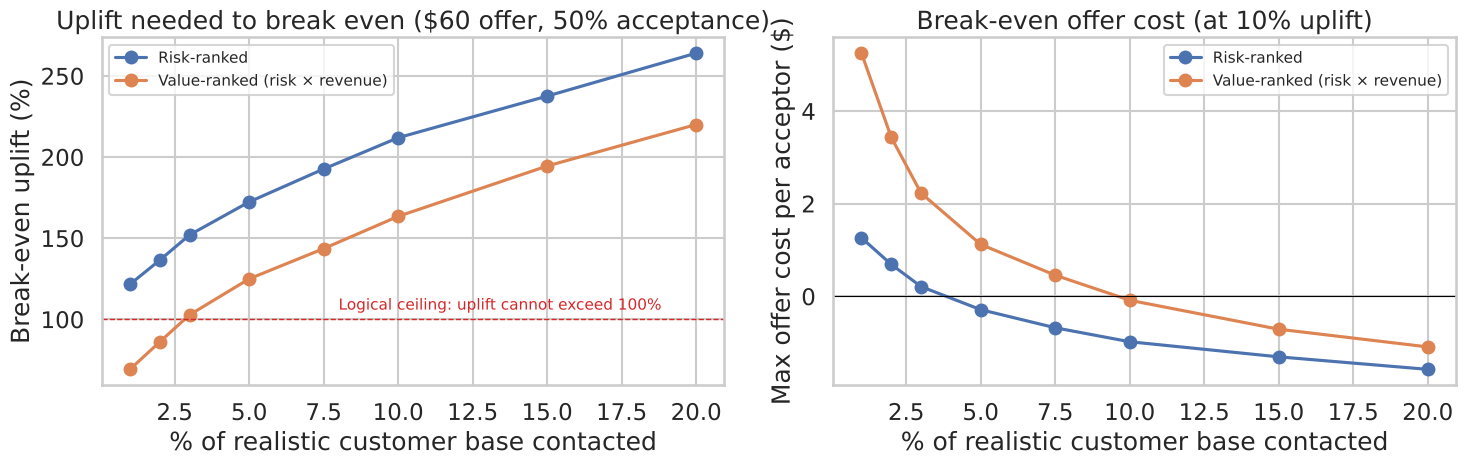

,depth,ranking,list size,list precision,value per saved customer,break-even uplift,break-even offer cost
0,0.010,Risk-ranked,1000.849,0.117,225.449,1.216,1.263
1,0.010,Value-ranked (risk × revenue),1000.419,0.058,796.349,0.692,5.252
2,0.020,Risk-ranked,2007.090,0.095,247.075,1.365,0.690
3,0.020,Value-ranked (risk × revenue),2002.482,0.054,688.030,0.861,3.432
4,0.030,Risk-ranked,3000.619,0.084,251.240,1.520,0.210
5,0.030,Value-ranked (risk × revenue),3005.179,0.050,627.613,1.028,2.228
6,0.050,Risk-ranked,5009.184,0.071,261.280,1.724,-0.287
7,0.050,Value-ranked (risk × revenue),5004.318,0.045,570.152,1.250,1.122
8,0.075,Risk-ranked,7509.325,0.062,267.481,1.927,-0.678
9,0.075,Value-ranked (risk × revenue),7501.462,0.043,518.452,1.436,0.457


In [49]:
score_risk = p_test                         # risk-only ranking (unaffected by calibration)
score_value = value_score(MED["c"])         # value ranking, calibrated to the medium churn scenario
depths = [0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20]
curve = []
for d in depths:
    for name, sc in [("Risk-ranked", score_risk), ("Value-ranked (risk × revenue)", score_value)]:
        r = econ(list_by_depth(sc, d, MED["c"]), **MED)
        curve.append({"depth": d, "ranking": name, **r})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, g in curve.groupby("ranking"):
    axes[0].plot(g.depth * 100, g["break-even uplift"] * 100, "o-", label=name)
    axes[1].plot(g.depth * 100, g["break-even offer cost"], "o-", label=name)
axes[0].axhline(100, color="#d62728", ls="--", lw=1)
axes[0].text(8, 106, "Logical ceiling: uplift cannot exceed 100%", color="#d62728", fontsize=11)
axes[0].set(xlabel="% of realistic customer base contacted", ylabel="Break-even uplift (%)",
            title="Uplift needed to break even ($60 offer, 50% acceptance)")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="% of realistic customer base contacted", ylabel="Max offer cost per acceptor ($)",
            title="Break-even offer cost (at 10% uplift)")
for a_ in axes: a_.legend(fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig14_breakeven_depth.png", dpi=200); plt.show()
curve[["depth", "ranking", "list size", "list precision", "value per saved customer",
       "break-even uplift", "break-even offer cost"]].round(3)

**Reading the curves.**
- Value ranking lowers the break-even uplift sharply for shallow lists: it picks customers whose loss would cost the most, even though their churn probability is a little lower (precision falls, value per saved customer rises much more).
- Even so, with a **$60 offer** the break-even uplift stays far above any plausible uplift at every depth, and above 100% for deeper lists. A typical historical credit is too expensive for this customer base under a 12-month horizon.
- The break-even offer cost shows what *would* work: at 10% uplift, an action must cost **only a few dollars per acceptor**. Realistic candidates are low-cost or self-funding actions — a pre-renewal plan review, a handset upgrade financed by the customer in exchange for a new commitment, or fixing a service problem — rather than cash credits.

- Caution: the very shallowest value-ranked lists are dominated by a few very high-revenue customers (see "value per saved customer" at 1% depth), so results there are fragile. We use 2% rather than 1%.

**Design B (for the scale-up decision):** value-ranked, top **2%** of the base each month (≈2,000 customers), routed by segment (Section 6.2) to a low-cost action.

In [50]:
sel_B = list_by_depth(value_score(MED["c"]), 0.02, MED["c"])
rows = []
for c in P["c"]:
    for u in P["u"]:
        for o in [10, 35, 60]:                         # $10 = illustrative low-cost action; $35/$60 from O1
            r = econ(list_by_depth(value_score(c), 0.02, c), **{**MED, "c": c, "u": u, "o": o})
            rows.append({"churn c": c, "uplift u": u, "offer cost o": o, "list size": r["list size"],
                         "customers retained": r["customers retained"], "benefit": r["benefit (profit protected)"],
                         "cost": r["cost"], "net benefit": r["net benefit"], "ROI": r["ROI"],
                         "break-even uplift": r["break-even uplift"]})
design_B = pd.DataFrame(rows)
design_B.round(3)

,churn c,uplift u,offer cost o,list size,customers retained,benefit,cost,net benefit,ROI,break-even uplift
0,0.010,0.05,10,2009.210,2.815,1996.780,14064.468,-12067.689,-0.858,0.352
1,0.010,0.05,35,2009.210,2.815,1996.780,39179.590,-37182.811,-0.949,0.981
2,0.010,0.05,60,2009.210,2.815,1996.780,64294.712,-62297.932,-0.969,1.610
3,0.010,0.10,10,2009.210,5.630,3993.559,14064.468,-10070.909,-0.716,0.352
4,0.010,0.10,35,2009.210,5.630,3993.559,39179.590,-35186.031,-0.898,0.981
5,0.010,0.10,60,2009.210,5.630,3993.559,64294.712,-60301.153,-0.938,1.610
6,0.010,0.20,10,2009.210,11.259,7987.119,14064.468,-6077.350,-0.432,0.352
7,0.010,0.20,35,2009.210,11.259,7987.119,39179.590,-31192.472,-0.796,0.981
8,0.010,0.20,60,2009.210,11.259,7987.119,64294.712,-56307.594,-0.876,1.610
9,0.020,0.05,10,2002.482,5.408,3720.582,14017.371,-10296.790,-0.735,0.188


### 8.4b Old (uncalibrated) vs corrected (prior-adjusted) Design B

Same list size (top 2% of the realistic base), same assumptions ($10 action, 20% uplift, medium margin/acceptance/horizon); only the ranking differs.

In [51]:
rows = []
for c in P["c"]:
    s_old = list_by_depth(score_value_uncal, 0.02, c)
    s_new = list_by_depth(value_score(c), 0.02, c)
    for label, s_ in [("OLD: raw p x revenue", s_old), ("CORRECTED: adjusted p x revenue", s_new)]:
        r = econ(s_, **{**MED, "c": c, "o": 10, "u": 0.20})
        rows.append({"churn c": c, "ranking": label, "list size": r["list size"],
                     "would-be churners": r["would-be churners"], "list precision": r["list precision"],
                     "monthly revenue at risk": r["monthly revenue at risk"],
                     "value per saved customer": r["value per saved customer"], "net benefit": r["net benefit"],
                     "ROI": r["ROI"], "break-even uplift": r["break-even uplift"],
                     "overlap with other list": weights(c)[s_old & s_new].sum() / weights(c)[s_].sum()})   # weighted = share of realistic customers
calib_cmp = pd.DataFrame(rows)
calib_cmp.round(3)

,churn c,ranking,list size,would-be churners,list precision,monthly revenue at risk,value per saved customer,net benefit,ROI,break-even uplift,overlap with other list
0,0.010,OLD: raw p x revenue,2006.440,33.898,0.017,6942.983,1047.169,-6945.629,-0.495,0.396,0.644
1,0.010,CORRECTED: adjusted p x revenue,2009.210,56.295,0.028,7811.087,709.394,-6077.350,-0.432,0.352,0.644
2,0.020,OLD: raw p x revenue,2000.783,67.595,0.034,13832.780,991.263,-604.631,-0.043,0.209,0.663
3,0.020,CORRECTED: adjusted p x revenue,2002.482,108.152,0.054,15362.009,688.030,864.955,0.062,0.188,0.663
4,0.027,OLD: raw p x revenue,2000.987,91.253,0.046,18674.254,954.877,3420.164,0.244,0.161,0.673
5,0.027,CORRECTED: adjusted p x revenue,2005.062,143.553,0.072,20651.093,671.245,5236.456,0.373,0.146,0.672


**Interpretation.** The overlap column (weighted, i.e. share of *realistic* customers) shows how much of the list stays the same. A substantial share of the top-2% list changes once probabilities are adjusted. The corrected list holds more real would-be churners (the uncalibrated product over-rewarded high-revenue customers whose risk was only moderate), so the break-even uplift falls slightly. The direction of every conclusion is unchanged; the corrected numbers replace the old ones everywhere below.

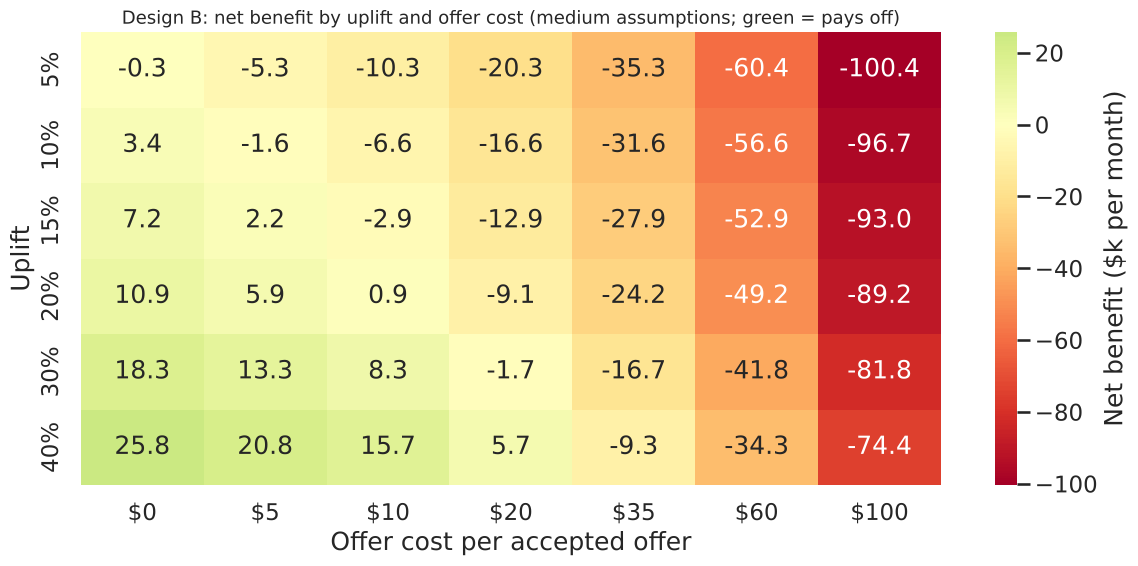

In [52]:
# Heatmap: net benefit of Design B for uplift x offer cost (medium churn, margin, acceptance, horizon)
ups = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
offers = [0, 5, 10, 20, 35, 60, 100]
grid = pd.DataFrame([[econ(sel_B, **{**MED, "u": u, "o": o})["net benefit"] for o in offers] for u in ups],
                    index=[f"{int(u*100)}%" for u in ups], columns=[f"${o}" for o in offers])
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(grid / 1000, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=ax,
            cbar_kws={"label": "Net benefit ($k per month)"})
ax.set_xlabel("Offer cost per accepted offer"); ax.set_ylabel("Uplift")
ax.set_title("Design B: net benefit by uplift and offer cost (medium assumptions; green = pays off)", fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig15_breakeven_heatmap.png", dpi=200); plt.show()

### 8.5 Sensitivity analysis (Design B, $10 low-cost action, 20% uplift as the reference point)

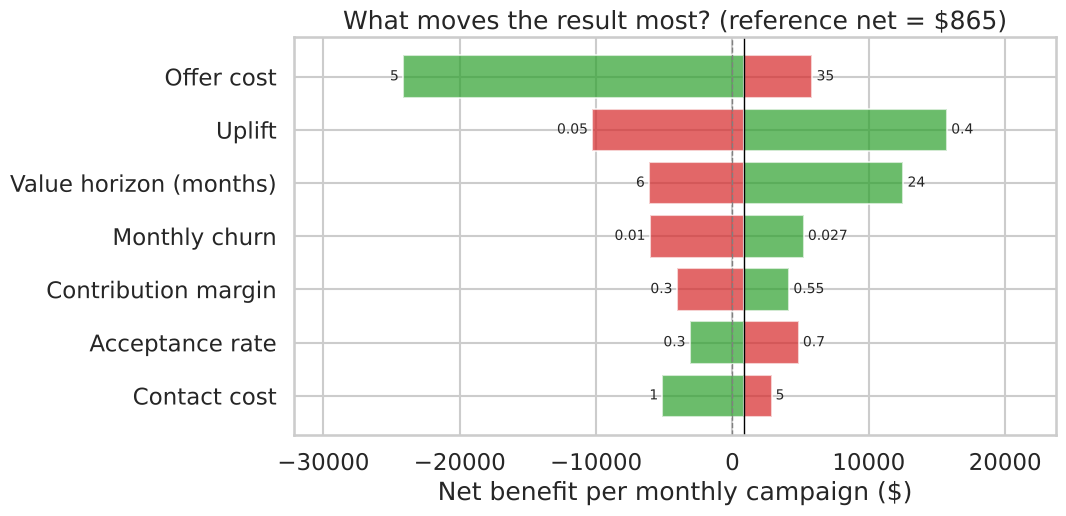

,parameter,low value,high value,net at low,net at high,swing
3,Contact cost,1.00,5.000,2867.437,-5142.490,8009.927
4,Acceptance rate,0.30,0.700,4869.918,-3140.008,8009.927
1,Contribution margin,0.30,0.550,-4095.821,4172.139,8267.959
0,Monthly churn,0.01,0.027,-6077.350,5236.456,11313.806
6,Value horizon (months),6.00,24.000,-6125.765,12543.365,18669.130
5,Uplift,0.05,0.400,-10296.790,15747.281,26044.071
2,Offer cost,5.00,35.000,5871.159,-24166.065,30037.224


In [53]:
ref = {**MED, "o": 10, "u": 0.20}
base_net = econ(sel_B, **ref)["net benefit"]
labels = {"c": "Monthly churn", "m": "Contribution margin", "o": "Offer cost", "k": "Contact cost",
          "a": "Acceptance rate", "u": "Uplift", "H": "Value horizon (months)"}
alt = {"o": (5, 35), "u": (0.05, 0.40)}              # ranges around the reference point
tor = []
for key, (lo, _, hi) in P.items():
    lo, hi = alt.get(key, (lo, hi))
    vals = []
    for v in (lo, hi):
        params = {**ref, key: v}
        sel = list_by_depth(value_score(params["c"]), 0.02, params["c"]) if key == "c" else sel_B
        vals.append(econ(sel, **params)["net benefit"])
    tor.append({"parameter": labels[key], "low value": lo, "high value": hi,
                "net at low": vals[0], "net at high": vals[1], "swing": abs(vals[1] - vals[0])})
tor = pd.DataFrame(tor).sort_values("swing")

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, r in enumerate(tor.itertuples()):
    ax.barh(i, r._4 - base_net, left=base_net, color="#d62728", alpha=0.7)
    ax.barh(i, r._5 - base_net, left=base_net, color="#2ca02c", alpha=0.7)
    ax.text(min(r._4, r._5) - 300, i, f"{r._2:g}", va="center", ha="right", fontsize=10)
    ax.text(max(r._4, r._5) + 300, i, f"{r._3:g}", va="center", ha="left", fontsize=10)
ax.axvline(base_net, color="black", lw=1); ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(range(len(tor))); ax.set_yticklabels(tor.parameter)
ax.set_xlabel("Net benefit per monthly campaign ($)")
ax.set_title(f"What moves the result most? (reference net = ${base_net:,.0f})")
ax.margins(x=0.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig16_tornado.png", dpi=200); plt.show()
tor.round(3)

**Reading the tornado.** The bars show how net benefit changes when one assumption moves from its low to its high value while everything else stays at the reference point. The longest bars are the assumptions that matter most — and therefore what the pilot and Company A's own data must pin down first. Uplift is the dominant unknown, which is exactly why the recommendation is built around measuring it.

### 8.6 Validation: the randomised controlled pilot

Because the model predicts risk, not response, the only way to learn whether an action works is to **randomly split** the selected customers:
- **Treatment group** receives the action; **control group** receives nothing (business as usual).
- After the churn window (days 31–60), compare churn rates. **Uplift = (control churn − treatment churn) ÷ control churn.**
- Randomisation guarantees the two groups are alike in everything except the action, so the difference is caused by the action — something no observational analysis (including our model) can show.

**How many customers does the pilot need?** Detecting a small change in a low churn rate requires large groups. Standard two-proportion sample-size formula, 5% significance, 80% power:

In [54]:
from scipy.stats import norm
def n_per_arm(p0, rel_uplift, alpha=0.05, power=0.80):
    p1 = p0 * (1 - rel_uplift)
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return int(np.ceil(z**2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p0 - p1) ** 2))

rows = []
for c in P["c"]:
    selc = list_by_depth(value_score(c), 0.02, c)
    p0 = econ(selc, **{**MED, "c": c})["list precision"]
    for u in [0.10, 0.20, 0.30]:
        n = n_per_arm(p0, u)
        rows.append({"churn c": c, "control churn on list": p0, "uplift to detect": u,
                     "customers per arm": n, "months of 2% lists needed (50/50 split)": 2 * n / (BASE * 0.02)})
# Faster alternative: pilot on a broader risk-ranked list (top 10% of base), where churn is more concentrated
for c in P["c"]:
    selc = list_by_depth(score_risk, 0.10, c)
    p0 = econ(selc, **{**MED, "c": c})["list precision"]
    for u in [0.10, 0.20, 0.30]:
        n = n_per_arm(p0, u)
        rows.append({"churn c": c, "control churn on list": p0, "uplift to detect": u,
                     "customers per arm": n, "months of 2% lists needed (50/50 split)": np.nan,
                     "months of 10% risk lists needed (50/50 split)": 2 * n / (BASE * 0.10)})
pilot = pd.DataFrame(rows)
pilot.round(3)

,churn c,control churn on list,uplift to detect,customers per arm,months of 2% lists needed (50/50 split),months of 10% risk lists needed (50/50 split)
0,0.010,0.028,0.1,51805,51.805,NaN
1,0.010,0.028,0.2,12285,12.285,NaN
2,0.010,0.028,0.3,5162,5.162,NaN
3,0.020,0.054,0.1,26192,26.192,NaN
4,0.020,0.054,0.2,6218,6.218,NaN
5,0.020,0.054,0.3,2616,2.616,NaN
6,0.027,0.072,0.1,19409,19.409,NaN
7,0.027,0.072,0.2,4612,4.612,NaN
8,0.027,0.072,0.3,1941,1.941,NaN
9,0.010,0.029,0.1,50763,NaN,10.153


**Implication.** On the small 2% value list, churn is only a few percent even without action, so detecting a 20% uplift needs many thousands of customers per group — many months of lists (table above). That is too slow. A **broader risk-ranked list (top 10% of the base)** has more churners per customer and reaches the same statistical power much faster. **Its purpose is only to measure intervention uplift; the narrower value-ranked list remains the proposed scale-up strategy.** Recommended pilot design: test the low-cost action on the broader risk list first to measure uplift quickly, then check whether the effect holds for high-value customers before scaling Design B. (Caveat: uplift measured on one group may differ in another; the pilot should report uplift by segment.) The pilot design and its success threshold (measured uplift > break-even uplift for the action's real cost) are defined *before* launch.

**What the pilot measures, separately.**
| Quantity | How it is measured | Observable? |
|---|---|---|
| Overall acceptance `a` | Acceptors ÷ customers offered, in the treatment group | **Yes**, directly |
| Uplift `u` (intention-to-treat) | (control churn − treatment churn) ÷ control churn, comparing the full groups whether or not customers accepted | **Yes**, by randomisation |
| Effect among acceptors (complier effect) | Absolute churn reduction (intention-to-treat) ÷ acceptance rate in the treatment group | **Yes**, estimated — valid only under the assumptions below |
| Acceptance among would-be churners `a_ch` | Would need to know which treated customers would have churned without the offer | **No** — counterfactual; only bounded |
| Acceptance by predicted-risk band or segment | Acceptance rate per risk decile / segment in the treatment group | **Yes** — a useful proxy for whether high-risk customers respond |

**Complier-effect estimate — assumptions.** Dividing the intention-to-treat churn reduction by the acceptance rate estimates the effect *among customers who accept* (a complier average causal effect). It is valid only if: (1) assignment to treatment/control is random; (2) the offer is available only to the treatment group, so no control customer can accept it (one-sided non-compliance); (3) being offered affects churn **only through accepting** (exclusion restriction — e.g. the contact itself does not change behaviour); (4) one customer's treatment does not affect another's churn. If the contact alone influences customers, this estimate is biased; the intention-to-treat uplift remains valid regardless.

**Outcome window.** Treatment and control churn are both measured over the **same 31–60-day window** after the pilot snapshot date, identical to the model's label definition, so the comparison is like-for-like.

### 8.7 Summary of the financial findings
1. **A blanket discount to the risk list loses money in every scenario** (Design A). This is a finding, not a failure: it prevents Company A from spending on the obvious-but-wrong programme.
2. **Value-weighted, shallow targeting improves the economics substantially**, but historically typical credits ($35–100) still require implausibly large uplift under a 12-month horizon.
3. **Low-cost actions are the only plausible route.** Break-even uplift for a $10 action on the (calibrated) Design B list is printed below for each churn scenario. Whether a 20% uplift is achievable is unknown — that is precisely what the pilot must establish.
5. **The value horizon is the second-largest lever after cost and uplift.** Tying the action to a new commitment (e.g. handset upgrade with recommitment) could lengthen the period over which a saved customer's margin is earned.
4. **Uplift is the decisive unknown**; the pilot measures it. Scale only actions whose measured uplift exceeds their break-even uplift.

### 8.8 Audit: independent re-computation of key numbers

Each check below recomputes a reported number a **different way** and asserts the two agree.
1. Design A (medium) recomputed from raw counts and closed-form TPR/FPR, without the `econ` helper.
2. Break-even uplift verified by plugging it back in: net benefit must be ≈ 0.
3. Break-even offer cost verified the same way.
4. Pilot sample size cross-checked against `statsmodels` power analysis (different method: Cohen's *h* effect size).
5. Uplift ≤ min(1, a / list precision) enforced in every scenario (assertion inside `econ`; Section 8.2b).

In [55]:
# 1. Design A, medium, recomputed from first principles
c, m, o, k, a, u, H = MED["c"], MED["m"], MED["o"], MED["k"], MED["a"], MED["u"], MED["H"]
flag = p_test >= np.quantile(p_test, 0.8)
tpr = flag[Y_T == 1].mean(); fpr = flag[Y_T == 0].mean()
L_hand = BASE * (c * tpr + (1 - c) * fpr)
C_hand = BASE * c * tpr
rev_hand = REV_VALUE[flag & (Y_T == 1)].mean()            # equal weights within churners -> simple mean
V_hand = rev_hand * m * sum((1 - c) ** t for t in range(H))
B_hand = C_hand * u * V_hand
K_hand = L_hand * k + L_hand * a * o
r = econ(sel_A, **MED)
checks = {"list size": (L_hand, r["list size"]), "would-be churners": (C_hand, r["would-be churners"]),
          "benefit": (B_hand, r["benefit (profit protected)"]), "cost": (K_hand, r["cost"])}
for name, (x1, x2) in checks.items():
    assert np.isclose(x1, x2, rtol=1e-6), name
    print(f"{name:20s} hand={x1:14,.2f}  econ={x2:14,.2f}  OK")

# 2-3. Break-even values plugged back in
be_u = r["break-even uplift"]
print("Net at break-even uplift (Design B, $10):",
      round(econ(sel_B, **{**MED, "o": 10, "u": min(econ(sel_B, **{**MED, "o": 10})["break-even uplift"], 0.5)})["net benefit"], 6))
rb = econ(sel_B, **{**MED, "u": 0.20})
print("Net at break-even offer cost (Design B, 20% uplift):",
      round(econ(sel_B, **{**MED, "u": 0.20, "o": rb["break-even offer cost"]})["net benefit"], 6))

# 4. Pilot sample size: closed form vs statsmodels (Cohen's h)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
for p0, rel in [(0.034, 0.20), (0.056, 0.20), (0.034, 0.10)]:
    n_closed = n_per_arm(p0, rel)
    n_sm = NormalIndPower().solve_power(effect_size=proportion_effectsize(p0, p0 * (1 - rel)), alpha=0.05, power=0.8)
    print(f"p0={p0:.3f}, uplift={rel:.0%}: closed-form n={n_closed:,} | statsmodels n={int(np.ceil(n_sm)):,}")

list size            hand=     10,766.94  econ=     10,766.94  OK
would-be churners    hand=        595.84  econ=        595.84  OK
benefit              hand=     16,097.03  econ=     16,097.03  OK
cost                 hand=    344,542.01  econ=    344,542.01  OK
Net at break-even uplift (Design B, $10): 0.0
Net at break-even offer cost (Design B, 20% uplift): 0.0
p0=0.034, uplift=20%: closed-form n=10,067 | statsmodels n=10,040
p0=0.056, uplift=20%: closed-form n=5,986 | statsmodels n=5,972
p0=0.034, uplift=10%: closed-form n=42,441 | statsmodels n=42,416


### 8.9 Audit finding: the value of a saved customer may be overstated

`H_eff` assumes a saved customer then churns at the **average** monthly rate `c`. But saved customers were high-risk; they may keep leaving at a higher rate. Stress test: assume a saved customer churns each month at the list's own churn rate (its precision).

In [56]:
rows_stress = []
for label, sel_x, o_x in [("Design B, $10 action", sel_B, 10), ("Design A, $60 offer", sel_A, 60)]:
    base_r = econ(sel_x, **{**MED, "o": o_x, "u": 0.20})
    hz = base_r["list precision"]                                # elevated post-save churn
    H_eff_stress = sum((1 - hz) ** t for t in range(MED["H"]))
    H_eff_base = sum((1 - MED["c"]) ** t for t in range(MED["H"]))
    V_s = base_r["value per saved customer"] * H_eff_stress / H_eff_base
    B_s = base_r["would-be churners"] * 0.20 * V_s
    rows_stress.append({"design": label, "monthly churn after save": hz, "H_eff (base)": H_eff_base, "H_eff (stress)": H_eff_stress,
                 "net (base)": base_r["net benefit"], "net (stress)": B_s - base_r["cost"],
                 "break-even uplift (base)": base_r["break-even uplift"],
                 "break-even uplift (stress)": base_r["cost"] / (base_r["would-be churners"] * V_s)})
pd.DataFrame(rows_stress).round(3)

,design,monthly churn after save,H_eff (base),H_eff (stress),net (base),net (stress),break-even uplift (base),break-even uplift (stress)
0,"Design B, $10 action",0.054,10.764,9.005,864.955,-1566.545,0.188,0.225
1,"Design A, $60 offer",0.055,10.764,8.944,-312347.952,-317790.641,2.140,2.576


**Interpretation.** If saved customers keep churning at their elevated rate, the value of a save falls modestly and the break-even uplift rises. The direction of every conclusion is unchanged (Design A still fails; Design B still requires a low-cost action and ~20%+ uplift), but the medium-case numbers should be read as **slightly optimistic**.

**Other audit notes**
- *Margin vs revenue:* benefit uses `revenue × margin × H_eff`; revenue is never counted as profit.
- *Acceptance vs uplift:* acceptance only enters cost (actual acceptors × offer cost); uplift only enters benefit (measured incremental saves). The logical bound is u ≤ min(1, a / list precision), not u ≤ a.
- *Time horizons:* the offer cost is a one-off cost per campaign; benefit is the margin of saved customers over `H` months. Both refer to the same monthly campaign cohort; nothing is annualised.
- *Uplift definition matches the pilot:* the pilot measures intention-to-treat uplift (everyone on the list randomised, whether or not they accept), which is exactly the `C × u` quantity in the model.
- *Not independently verifiable:* contact cost, acceptance rate, uplift and value horizon have no external source; they are illustrative and labelled as such.

In [57]:
for c in P["c"]:
    be = econ(list_by_depth(value_score(c), 0.02, c), **{**MED, "c": c, "o": 10})["break-even uplift"]
    print(f"Design B ($10 action), churn {c:.1%}: break-even uplift = {be:.1%}")

Design B ($10 action), churn 1.0%: break-even uplift = 35.2%
Design B ($10 action), churn 2.0%: break-even uplift = 18.8%
Design B ($10 action), churn 2.7%: break-even uplift = 14.6%


## 9. Freeze: save final results

In [58]:
import json
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

def _month_ci(mo):
    """Churn rate and 95% Wilson CI for one tenure month (same method as Section 2.1)."""
    k_, n_ = int(df.loc[df.months == mo, "churn"].sum()), int((df.months == mo).sum())
    lo_, hi_ = proportion_confint(k_, n_, method="wilson")
    return {"month": int(mo), "rate": k_ / n_, "n": n_, "churners": k_, "ci_low": float(lo_), "ci_high": float(hi_)}
summary = {
    "data": {"customers": int(len(df)), "sample_churn_rate": float(df.churn.mean()),
             "train_size": int(len(X_train)), "test_size": int(len(X_test)), "n_features": int(X.shape[1])},
    "hypothesis_validation": {"churn_month9": float(df.loc[df.months == 9, "churn"].mean()), "churn_month11": float(df.loc[df.months == 11, "churn"].mean()),
                              "window_OR_M3": float(np.exp(models[list(forms)[-1]].params.win)),
                              "handset_OR_per_year_M3": float(np.exp(models[list(forms)[-1]].params.eqp_years))},
    "cv_logreg": lr_folds.drop(columns="fold").mean().to_dict(),
    "cv_lgbm_default": lgb_folds.drop(columns="fold").mean().to_dict(),
    "cv_lgbm_conservative": lgbr_folds.drop(columns="fold").mean().to_dict(),
    "cv_lgbm_conservative_sd": lgbr_folds.drop(columns="fold").std().to_dict(),
    "test_lgbm_conservative": {k_: float(v) for k_, v in test_m.items()},
    "confusion_test": cm_test.tolist(),
    "financial_designA_medium": {k_: float(v) for k_, v in econ(sel_A, **MED).items()},
    "financial_designB_medium_10usd_20pct": {k_: float(v) for k_, v in econ(sel_B, **{**MED, "o": 10, "u": 0.20}).items()},
    "designB_breakeven_10usd_by_churn": {str(c): float(econ(list_by_depth(value_score(c), 0.02, c), **{**MED, "c": c, "o": 10})["break-even uplift"]) for c in P["c"]},
    "designB_breakeven_35_60usd_medium": {str(o): float(econ(sel_B, **{**MED, "o": o})["break-even uplift"]) for o in (35, 60)},
    "designB_heatmap_net": {f"u{int(u*100)}_o{o}": float(econ(sel_B, **{**MED, "u": u, "o": o})["net benefit"]) for u in ups for o in offers},
    "designA_vs_random_medium": {"model_be_u": float(econ(sel_A, **MED)["break-even uplift"])},
    "pilot": pilot.to_dict(orient="records"),
    "calibration_comparison": calib_cmp.to_dict(orient="records"),
    "stress_test": pd.DataFrame(rows_stress).to_dict(orient="records"),
    "segments": seg.reset_index().to_dict(orient="records"),
    "decile_test": dec.reset_index().astype({"risk_decile": int}).to_dict(orient="records"),
    "rev_mean": float(df.rev_Mean.mean()), "rev_median": float(df.rev_Mean.median()),
    "tpr20": float(tpr20), "fpr20": float(fpr20),
    "scenario_table": scen_df.to_dict(orient="records"),
    "acceptance_feasibility": feasibility.to_dict(orient="records"),
    "chart_data": {
        "churn_by_month": [_month_ci(mo) for mo in range(6, 19)],
        "odds_ratios_M3": {k_: float(v) for k_, v in ort["OR"].items()},
        "tenure_handset_heatmap": {"index": [str(i) for i in piv.index], "columns": [str(c_) for c_ in piv.columns],
                                   "values": [[None if pd.isna(v) else float(v) for v in row] for row in piv.values]},
        "shap_tenure": {str(int(k_)): float(v) for k_, v in sm.items()},
        "shap_handset": {f"{int(b.left)}-{int(b.right)}": float(v) for b, v in sb.items()},
        "shap_importance_top10": {k_: float(v) for k_, v in imp_df["mean |SHAP|"].head(10).items()},
        "gains_test": [{"pct_contacted": q, "pct_churners": float(np.cumsum(y_test.values[np.argsort(-p_test)])[int(q / 100 * len(p_test)) - 1] / y_test.sum())}
                       for q in range(5, 101, 5)],
        "depth_curve": curve[["depth", "ranking", "break-even uplift", "list precision"]].to_dict(orient="records"),
    },
    "extra": {
        "churn_month10": float(df.loc[df.months == 10, "churn"].mean()),
        "churn_month12": float(df.loc[df.months == 12, "churn"].mean()),
        "window_OR_M1": float(np.exp(models[list(forms)[0]].params.win)),
        "window_OR_M2": float(np.exp(models[list(forms)[1]].params.win)),
        "max_single_feature_auc": float(auc.drop("Customer_ID").max()),
        "shap_top4": list(imp_df.index[:4]),
        "example_customers": {lab: {"months": int(test_df.loc[i, "months"]), "p": float(test_df.loc[i, "p_churn"]),
                                    "change_mou": float(test_df.loc[i, "change_mou"]), "rev": float(test_df.loc[i, "rev_Mean"])}
                              for lab, i in examples.items()},
    },
}
(RES / "metrics.json").write_text(json.dumps(summary, indent=2))
design_A.to_csv(RES / "design_A_scenarios.csv", index=False)
design_B.to_csv(RES / "design_B_scenarios.csv", index=False)
seg.to_csv(RES / "segments_test_top20.csv")
pilot.to_csv(RES / "pilot_sample_sizes.csv", index=False)
tor.to_csv(RES / "sensitivity_tornado.csv", index=False)
calib_cmp.to_csv(RES / "calibration_comparison.csv", index=False)
print("Saved:", sorted(p.name for p in RES.iterdir()))

Saved: ['calibration_comparison.csv', 'design_A_scenarios.csv', 'design_B_scenarios.csv', 'metrics.json', 'pilot_sample_sizes.csv', 'segments_test_top20.csv', 'sensitivity_tornado.csv']
